In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

## TLS/TLSCL inference results

In [3]:
DATASET = "TLSC"
DATA_DIR = f"../data/troupe/{DATASET}"

In [4]:
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import re
import sys

import pandas as pd
import torch

project_root = Path(DATA_DIR).resolve().parents[2]
sys.path.insert(0, str(project_root))

from src.closed_form_coord2 import calculate_Us, calculate_log_likelihood
from src.tree_utils import cut_tree, get_datastructure_for_likelihood_calculation

inference_path = Path(DATA_DIR) / "inference.out"
inference_lines = inference_path.read_text().splitlines()


def parse_inference_vector(name):
    prefix = f"{name}:"
    line = next(line for line in inference_lines if line.startswith(prefix))
    return [float(value) for value in line[len(prefix):].split()]


fitted_log_likelihood = float(
    next(line.split("=", 1)[1] for line in inference_lines if line.startswith("LL="))
)
birth_rates = torch.tensor(parse_inference_vector("birth"), dtype=torch.float64)
death_rates = torch.tensor(parse_inference_vector("death"), dtype=torch.float64)
sampling_probabilities = torch.tensor(
    parse_inference_vector("sampling"), dtype=torch.float64
)
num_states = len(birth_rates)

transition_probabilities = torch.zeros((num_states, num_states), dtype=torch.float64)
in_transitions = False
for line in inference_lines:
    if line == "transitions:":
        in_transitions = True
        continue
    if line == "transition_times:":
        in_transitions = False
        continue
    if in_transitions:
        match = re.fullmatch(r"(\d+)->(\d+)\s+([0-9.eE+-]+)", line.strip())
        if match:
            source, target, probability = match.groups()
            transition_probabilities[int(source), int(target)] = float(probability)

transition_times = []
in_transition_times = False
for line in inference_lines:
    if line == "transition_times:":
        in_transition_times = True
        continue
    if in_transition_times and line.strip():
        fields = line.split()
        if len(fields) == 2 and fields[0].isdigit():
            transition_times.append(float(fields[1]))

if not torch.allclose(
    transition_probabilities.sum(dim=1),
    torch.ones(num_states, dtype=torch.float64),
    atol=1e-6,
):
    raise ValueError("The transition matrix in inference.out is not row-stochastic")
if len(death_rates) != num_states or len(sampling_probabilities) != num_states:
    raise ValueError("Inferred rate vectors have inconsistent state counts")

print("Loaded inferred parameters from", inference_path)
print(f"Fitted log-likelihood: {fitted_log_likelihood:.6f}")
print("Birth rates:", birth_rates.tolist())
print("Death rates:", death_rates.tolist())
print("Sampling probabilities:", sampling_probabilities.tolist())
print("Transition probabilities:")
print(transition_probabilities)
print("Transition times:", transition_times)


Loaded inferred parameters from ../data/troupe/TLSC/inference.out
Fitted log-likelihood: -3090.800167
Birth rates: [7.02100446335704, 4.39745996098746, 5.50055911121979]
Death rates: [0.530137834257106, 1.47432694447983, 5.50055906359777]
Sampling probabilities: [0.125085528060102, 0.125085528060102, 0.125085528060102]
Transition probabilities:
tensor([[0.8805, 0.0697, 0.0498],
        [0.0000, 1.0000, 0.0000],
        [0.0000, 0.0000, 1.0000]])
Transition times: [0.0001, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]


In [5]:
from src.dataprocessor import load_edges, load_nodes
from src.tree_utils import prepare_nx_tree

num_states = len(birth_rates)
subtree_export_dir = Path(DATA_DIR) / "subtrees_kept_states"
node_files = sorted(subtree_export_dir.glob("tree_*/subtree_*/nodes.csv"))
if not node_files:
    raise FileNotFoundError(f"No exported subtree nodes found under {subtree_export_dir}")

subtree_specs = []
for node_file in node_files:
    edge_file = node_file.with_name("edges.csv")
    if not edge_file.exists():
        raise FileNotFoundError(f"Missing edge file for {node_file}")

    with redirect_stdout(StringIO()):
        nodes = load_nodes(str(node_file))
        edges = load_edges(str(edge_file))
    subtree = prepare_nx_tree(nodes, edges)

    invalid_leaf_states = [
        node.state for node in nodes if node.is_leaf and not 0 <= node.state < num_states
    ]
    if invalid_leaf_states:
        raise ValueError(
            f"Invalid leaf states in {node_file}: {sorted(set(invalid_leaf_states))}"
        )

    root = subtree.graph["root"]
    subtree_specs.append(
        {
            "tree": node_file.parents[1].name,
            "subtree": node_file.parent.name,
            "path": node_file.parent,
            "graph": subtree,
            "root_time": float(subtree.nodes[root]["T"]),
        }
    )

root_times = [spec["root_time"] for spec in subtree_specs]
subtree_likelihood_inputs = []
for spec in subtree_specs:
    subtree = spec["graph"]
    applicable_transition_times = [
        time for time in transition_times if time < spec["root_time"]
    ]
    levels, hierarchy = cut_tree(subtree, applicable_transition_times)
    with redirect_stdout(StringIO()):
        datastructure = get_datastructure_for_likelihood_calculation(
            levels,
            hierarchy,
            applicable_transition_times,
            num_states,
        )
    subtree_likelihood_inputs.append(
        (spec, applicable_transition_times, datastructure)
    )

u_result = calculate_Us(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_probabilities=sampling_probabilities,
    transition_probabilities=transition_probabilities,
    transition_times=torch.tensor(transition_times, dtype=torch.float64),
    root_times=root_times,
)

subtree_likelihood_rows = []
for spec, subtree_transition_times, datastructure in subtree_likelihood_inputs:
    subtree = spec["graph"]
    root_time = spec["root_time"]
    loglikelihood_by_root_state = calculate_log_likelihood(
        datastructure=datastructure,
        birth_rates=birth_rates,
        death_rates=death_rates,
        transition_probabilities=transition_probabilities,
        sampling_probabilities=sampling_probabilities,
        Cs=u_result.Cs[: len(subtree_transition_times) + 1],
        transition_times=subtree_transition_times,
    )
    subtree_likelihood_rows.append(
        {
            "tree": spec["tree"],
            "subtree": spec["subtree"],
            "root": subtree.graph["root"],
            "root_time": root_time,
            "nodes": subtree.number_of_nodes(),
            "leaves": sum(
                1 for node in subtree if subtree.out_degree(node) == 0
            ),
            "epochs_before_root": len(subtree_transition_times),
            "log_likelihood": float(loglikelihood_by_root_state[0, 0]),
        }
    )

subtree_likelihoods = pd.DataFrame(subtree_likelihood_rows)
total_subtree_loglikelihood = subtree_likelihoods["log_likelihood"].sum()
print(
    f"Evaluated {len(subtree_likelihoods)} subtrees across "
    f"{subtree_likelihoods['tree'].nunique()} trees."
)
print(subtree_likelihoods.to_string(index=False))
print("Summed subtree log-likelihood:", total_subtree_loglikelihood)

Evaluated 103 subtrees across 11 trees.
    tree     subtree  root  root_time  nodes  leaves  epochs_before_root  log_likelihood
tree_001 subtree_001     0   0.720191      2       1                  15       -2.641962
tree_001 subtree_002     0   0.729600      2       1                  15       -2.667445
tree_001 subtree_003     0   0.739009      2       1                  15       -2.694449
tree_001 subtree_004     0   0.748418      2       1                  15       -2.722932
tree_001 subtree_005     0   0.895614     18       9                  18       -6.342304
tree_001 subtree_006     0   0.905023      8       4                  19       -3.487259
tree_001 subtree_007     0   0.914432      2       1                  19       -2.935195
tree_001 subtree_008     0   0.923841      2       1                  19       -2.965910
tree_001 subtree_009     0   0.933250     32      16                  19      -14.987718
tree_001 subtree_010     0   0.962365    368     184                  

In [6]:
original_first_birth_rate = float(birth_rates[0])
birth_rate_grid = torch.linspace(
    original_first_birth_rate - 2.0,
    original_first_birth_rate + 2.0,
    steps=41,
    dtype=torch.float64,
)
birth_rate_grid[20] = original_first_birth_rate

sensitivity_inputs = [
    (applicable_transition_times, datastructure)
    for _, applicable_transition_times, datastructure in subtree_likelihood_inputs
]
sensitivity_rows = []
for candidate_birth_rate in birth_rate_grid:
    trial_birth_rates = birth_rates.clone()
    trial_birth_rates[0] = candidate_birth_rate
    trial_u_result = calculate_Us(
        birth_rates=trial_birth_rates,
        death_rates=death_rates,
        sampling_probabilities=sampling_probabilities,
        transition_probabilities=transition_probabilities,
        transition_times=torch.tensor(transition_times, dtype=torch.float64),
        root_times=root_times,
    )

    trial_subtree_loglikelihoods = []
    for applicable_transition_times, datastructure in sensitivity_inputs:
        loglikelihood_by_root_state = calculate_log_likelihood(
            datastructure=datastructure,
            birth_rates=trial_birth_rates,
            death_rates=death_rates,
            transition_probabilities=transition_probabilities,
            sampling_probabilities=sampling_probabilities,
            Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
            transition_times=applicable_transition_times,
        )
        trial_subtree_loglikelihoods.append(
            float(loglikelihood_by_root_state[0, 0])
        )

    sensitivity_rows.append(
        {
            "first_birth_rate": float(candidate_birth_rate),
            "summed_log_likelihood": sum(trial_subtree_loglikelihoods),
        }
    )

birth_rate_sensitivity = pd.DataFrame(sensitivity_rows)
baseline_loglikelihood = float(
    birth_rate_sensitivity.loc[
        birth_rate_sensitivity["first_birth_rate"] == original_first_birth_rate,
        "summed_log_likelihood",
    ].iloc[0]
)
birth_rate_sensitivity["change_from_baseline"] = (
    birth_rate_sensitivity["summed_log_likelihood"] - baseline_loglikelihood
)

likelihood_min = birth_rate_sensitivity["summed_log_likelihood"].min()
likelihood_max = birth_rate_sensitivity["summed_log_likelihood"].max()
best_sensitivity_row = birth_rate_sensitivity.loc[
    birth_rate_sensitivity["summed_log_likelihood"].idxmax()
]

print(
    f"Swept the first birth rate from {birth_rate_grid[0].item():.6f} to "
    f"{birth_rate_grid[-1].item():.6f} across {len(birth_rate_grid)} values."
)
print("All other inferred parameters were held fixed.")
print(f"Baseline summed log-likelihood: {baseline_loglikelihood:.6f}")
print(
    f"Likelihood range: {likelihood_min:.6f} to {likelihood_max:.6f} "
    f"(span {likelihood_max - likelihood_min:.6f})."
)
print(
    "Highest likelihood in sweep at first birth rate "
    f"{best_sensitivity_row['first_birth_rate']:.6f}: "
    f"{best_sensitivity_row['summed_log_likelihood']:.6f}"
)
print(birth_rate_sensitivity.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

Swept the first birth rate from 5.021004 to 9.021004 across 41 values.
All other inferred parameters were held fixed.
Baseline summed log-likelihood: -3140.904664
Likelihood range: -3548.861789 to -3140.904664 (span 407.957124).
Highest likelihood in sweep at first birth rate 7.021004: -3140.904664
 first_birth_rate  summed_log_likelihood  change_from_baseline
         5.021004           -3548.861789           -407.957124
         5.121004           -3506.568612           -365.663947
         5.221004           -3466.920198           -326.015534
         5.321004           -3429.858375           -288.953710
         5.421004           -3395.325262           -254.420598
         5.521004           -3363.263265           -222.358600
         5.621004           -3333.615077           -192.710412
         5.721004           -3306.323705           -165.419040
         5.821004           -3281.332497           -140.427832
         5.921004           -3258.585182           -117.680518
       

Ran one-at-a-time sensitivity for 11 fitted parameters; transition times were held fixed.
Birth/death rates: additive +/-2, bounded to keep rates positive and birth > death.
Sampling and free transition probabilities: relative +/-20%.
Transition row diagonals are adjusted to preserve row sums.
       parameter  tested_min  tested_max  likelihood_min  likelihood_max  likelihood_span  best_tested_value
        birth[0]    5.021004    9.021004    -3548.861789    -3140.904664       407.957124           7.021004
        birth[1]    2.397460    6.397460    -3356.263609    -3140.904664       215.358945           4.397460
        birth[2]    5.500559    7.500559    -3184.532718    -3140.900520        43.632198           5.500559
        death[0]    0.000000    2.530138    -3403.118180    -3139.357644       263.760537           0.371096
        death[1]    0.000000    3.474327    -3304.539612    -3140.638334       163.901279           1.400611
        death[2]    3.500559    5.500559    -3189.4

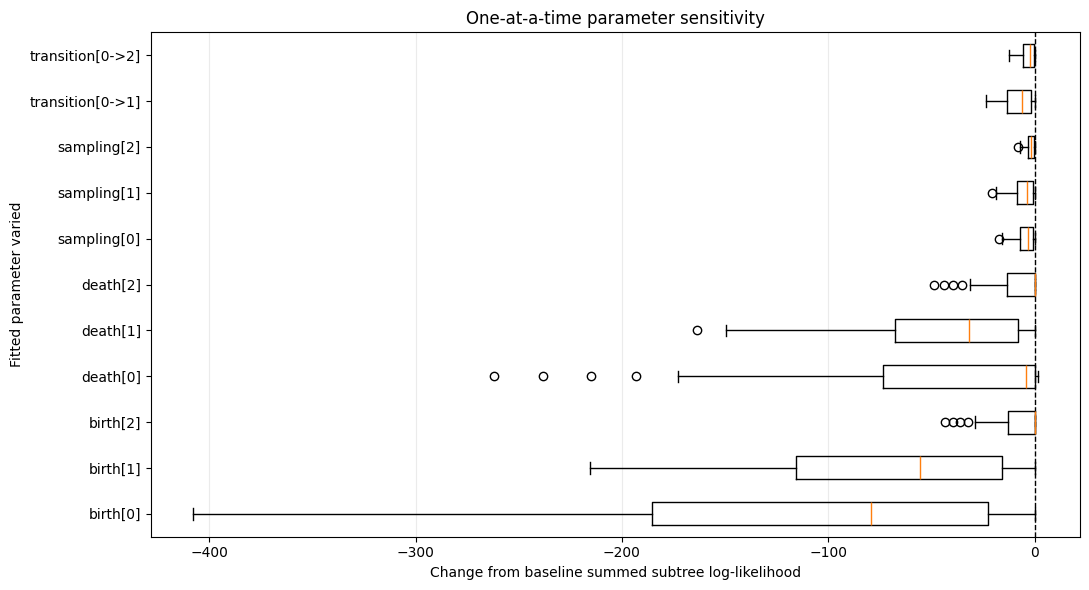

In [7]:
import matplotlib.pyplot as plt


def make_sensitivity_grid(original_value, lower_bound, upper_bound, points_per_side=20):
    original_value = float(original_value)
    if not lower_bound <= original_value <= upper_bound:
        raise ValueError("Sensitivity bounds must contain the original parameter")

    values = [torch.tensor([original_value], dtype=torch.float64)]
    if lower_bound < original_value:
        values.insert(
            0,
            torch.linspace(
                lower_bound,
                original_value,
                points_per_side + 1,
                dtype=torch.float64,
            )[:-1],
        )
    if upper_bound > original_value:
        values.append(
            torch.linspace(
                original_value,
                upper_bound,
                points_per_side + 1,
                dtype=torch.float64,
            )[1:],
        )
    return torch.cat(values)


parameter_sweeps = []
rate_margin = 1e-10
rate_delta = 2.0
probability_fraction = 0.2

for state_index, original_value in enumerate(birth_rates):
    lower_bound = max(
        1e-10,
        float(original_value) - rate_delta,
        float(death_rates[state_index]) + rate_margin,
    )
    upper_bound = min(20.0, float(original_value) + rate_delta)
    parameter_sweeps.append(
        (
            f"birth[{state_index}]",
            "birth",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for state_index, original_value in enumerate(death_rates):
    lower_bound = max(1e-10, float(original_value) - rate_delta)
    upper_bound = min(
        20.0,
        float(original_value) + rate_delta,
        float(birth_rates[state_index]) - rate_margin,
    )
    parameter_sweeps.append(
        (
            f"death[{state_index}]",
            "death",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for state_index, original_value in enumerate(sampling_probabilities):
    lower_bound = max(1e-8, float(original_value) * (1.0 - probability_fraction))
    upper_bound = min(1.0 - 1e-8, float(original_value) * (1.0 + probability_fraction))
    parameter_sweeps.append(
        (
            f"sampling[{state_index}]",
            "sampling",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for target_state in (1, 2):
    original_value = float(transition_probabilities[0, target_state])
    other_outgoing_probability = sum(
        float(transition_probabilities[0, state])
        for state in range(1, num_states)
        if state != target_state
    )
    lower_bound = max(
        1e-8,
        original_value * (1.0 - probability_fraction),
    )
    upper_bound = min(
        original_value * (1.0 + probability_fraction),
        1.0 - other_outgoing_probability - 1e-8,
    )
    parameter_sweeps.append(
        (
            f"transition[0->{target_state}]",
            "transition",
            target_state,
            make_sensitivity_grid(original_value, lower_bound, upper_bound),
        )
    )

sensitivity_rows = []
for parameter_name, parameter_kind, parameter_index, parameter_values in parameter_sweeps:
    for candidate_value in parameter_values:
        trial_birth_rates = birth_rates.clone()
        trial_death_rates = death_rates.clone()
        trial_sampling_probabilities = sampling_probabilities.clone()
        trial_transition_probabilities = transition_probabilities.clone()

        if parameter_kind == "birth":
            trial_birth_rates[parameter_index] = candidate_value
        elif parameter_kind == "death":
            trial_death_rates[parameter_index] = candidate_value
        elif parameter_kind == "sampling":
            trial_sampling_probabilities[parameter_index] = candidate_value
        else:
            trial_transition_probabilities[0, parameter_index] = candidate_value
            trial_transition_probabilities[0, 0] = 1.0 - trial_transition_probabilities[0, 1:].sum()

        trial_u_result = calculate_Us(
            birth_rates=trial_birth_rates,
            death_rates=trial_death_rates,
            sampling_probabilities=trial_sampling_probabilities,
            transition_probabilities=trial_transition_probabilities,
            transition_times=torch.tensor(transition_times, dtype=torch.float64),
            root_times=root_times,
        )

        trial_total_loglikelihood = 0.0
        for (applicable_transition_times, datastructure) in sensitivity_inputs:
            loglikelihood_by_root_state = calculate_log_likelihood(
                datastructure=datastructure,
                birth_rates=trial_birth_rates,
                death_rates=trial_death_rates,
                transition_probabilities=trial_transition_probabilities,
                sampling_probabilities=trial_sampling_probabilities,
                Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
                transition_times=applicable_transition_times,
            )
            trial_total_loglikelihood += float(loglikelihood_by_root_state[0, 0])

        sensitivity_rows.append(
            {
                "parameter": parameter_name,
                "parameter_value": float(candidate_value),
                "summed_log_likelihood": trial_total_loglikelihood,
            }
        )

parameter_sensitivity = pd.DataFrame(sensitivity_rows)
parameter_sensitivity["change_from_baseline"] = (
    parameter_sensitivity["summed_log_likelihood"] - total_subtree_loglikelihood
)
parameter_order = [sweep[0] for sweep in parameter_sweeps]
parameter_summary_rows = []
for parameter_name, _, _, parameter_values in parameter_sweeps:
    parameter_results = parameter_sensitivity[
        parameter_sensitivity["parameter"] == parameter_name
    ]
    best_row = parameter_results.loc[parameter_results["summed_log_likelihood"].idxmax()]
    parameter_summary_rows.append(
        {
            "parameter": parameter_name,
            "tested_min": float(parameter_values[0]),
            "tested_max": float(parameter_values[-1]),
            "likelihood_min": parameter_results["summed_log_likelihood"].min(),
            "likelihood_max": parameter_results["summed_log_likelihood"].max(),
            "likelihood_span": parameter_results["summed_log_likelihood"].max()
            - parameter_results["summed_log_likelihood"].min(),
            "best_tested_value": best_row["parameter_value"],
        }
    )
parameter_sensitivity_summary = pd.DataFrame(parameter_summary_rows)

if not torch.isclose(
    torch.tensor(total_subtree_loglikelihood, dtype=torch.float64),
    torch.tensor(baseline_loglikelihood, dtype=torch.float64),
    atol=1e-8,
    rtol=1e-10,
):
    raise AssertionError("The current baseline likelihoods do not match")

print(
    f"Ran one-at-a-time sensitivity for {len(parameter_sweeps)} fitted parameters; "
    f"transition times were held fixed."
)
print("Birth/death rates: additive +/-2, bounded to keep rates positive and birth > death.")
print("Sampling and free transition probabilities: relative +/-20%.")
print("Transition row diagonals are adjusted to preserve row sums.")
print(parameter_sensitivity_summary.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

boxplot_values = [
    parameter_sensitivity.loc[
        parameter_sensitivity["parameter"] == parameter_name,
        "change_from_baseline",
    ].to_numpy()
    for parameter_name in parameter_order
]
figure_height = max(6, 0.38 * len(parameter_order))
fig, ax = plt.subplots(figsize=(11, figure_height))
ax.boxplot(boxplot_values, vert=False, tick_labels=parameter_order, showfliers=True)
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Change from baseline summed subtree log-likelihood")
ax.set_ylabel("Fitted parameter varied")
ax.set_title("One-at-a-time parameter sensitivity")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## New

In [8]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# --------------------------------------------------
# Total likelihood evaluator
# --------------------------------------------------

def evaluate_total_loglikelihood(
    birth_rates_current,
    death_rates_current,
    sampling_current,
):
    root_times = [spec["root_time"] for spec in subtree_specs]

    u_result = calculate_Us(
        birth_rates=birth_rates_current,
        death_rates=death_rates_current,
        sampling_probabilities=sampling_current,
        transition_probabilities=transition_probabilities,
        transition_times=torch.tensor(
            transition_times,
            dtype=torch.float64,
        ),
        root_times=root_times,
    )

    total_ll = 0.0

    for spec, subtree_transition_times, datastructure in subtree_likelihood_inputs:
        ll = calculate_log_likelihood(
            datastructure=datastructure,
            birth_rates=birth_rates_current,
            death_rates=death_rates_current,
            transition_probabilities=transition_probabilities,
            sampling_probabilities=sampling_current,
            Cs=u_result.Cs[: len(subtree_transition_times) + 1],
            transition_times=subtree_transition_times,
        )

        total_ll += float(ll[0, 0])

    return total_ll


baseline_ll = evaluate_total_loglikelihood(
    birth_rates,
    death_rates,
    sampling_probabilities,
)

print("Baseline LL =", baseline_ll)

Baseline LL = -3140.904664480401


In [26]:
from math import log

alphas = [0.5, 0.1, 1e-5, 1e-10, 1e-25]
ll_drops = [-log(alpha) for alpha in alphas]
print(ll_drops)

[0.6931471805599453, 2.3025850929940455, 11.512925464970229, 23.025850929940457, 57.564627324851145]


Required one-at-a-time parameter shifts for likelihood drops from baseline:
       parameter direction  likelihood_drop  baseline_value  required_value  parameter_change  absolute_change  relative_change_percent
        birth[0]  decrease         0.693147           7.021         6.97815        -0.0428573        0.0428573                -0.610415
        birth[0]  decrease          2.30259           7.021         6.90013         -0.120877         0.120877                 -1.72164
        birth[0]  decrease          11.5129           7.021         6.69708         -0.323926         0.323926                 -4.61367
        birth[0]  decrease          23.0259           7.021         6.54669         -0.474314         0.474314                 -6.75564
        birth[0]  decrease          57.5646           7.021         6.25438         -0.766623         0.766623                  -10.919
        birth[0]  increase         0.693147           7.021         7.16513          0.144122         0.1441

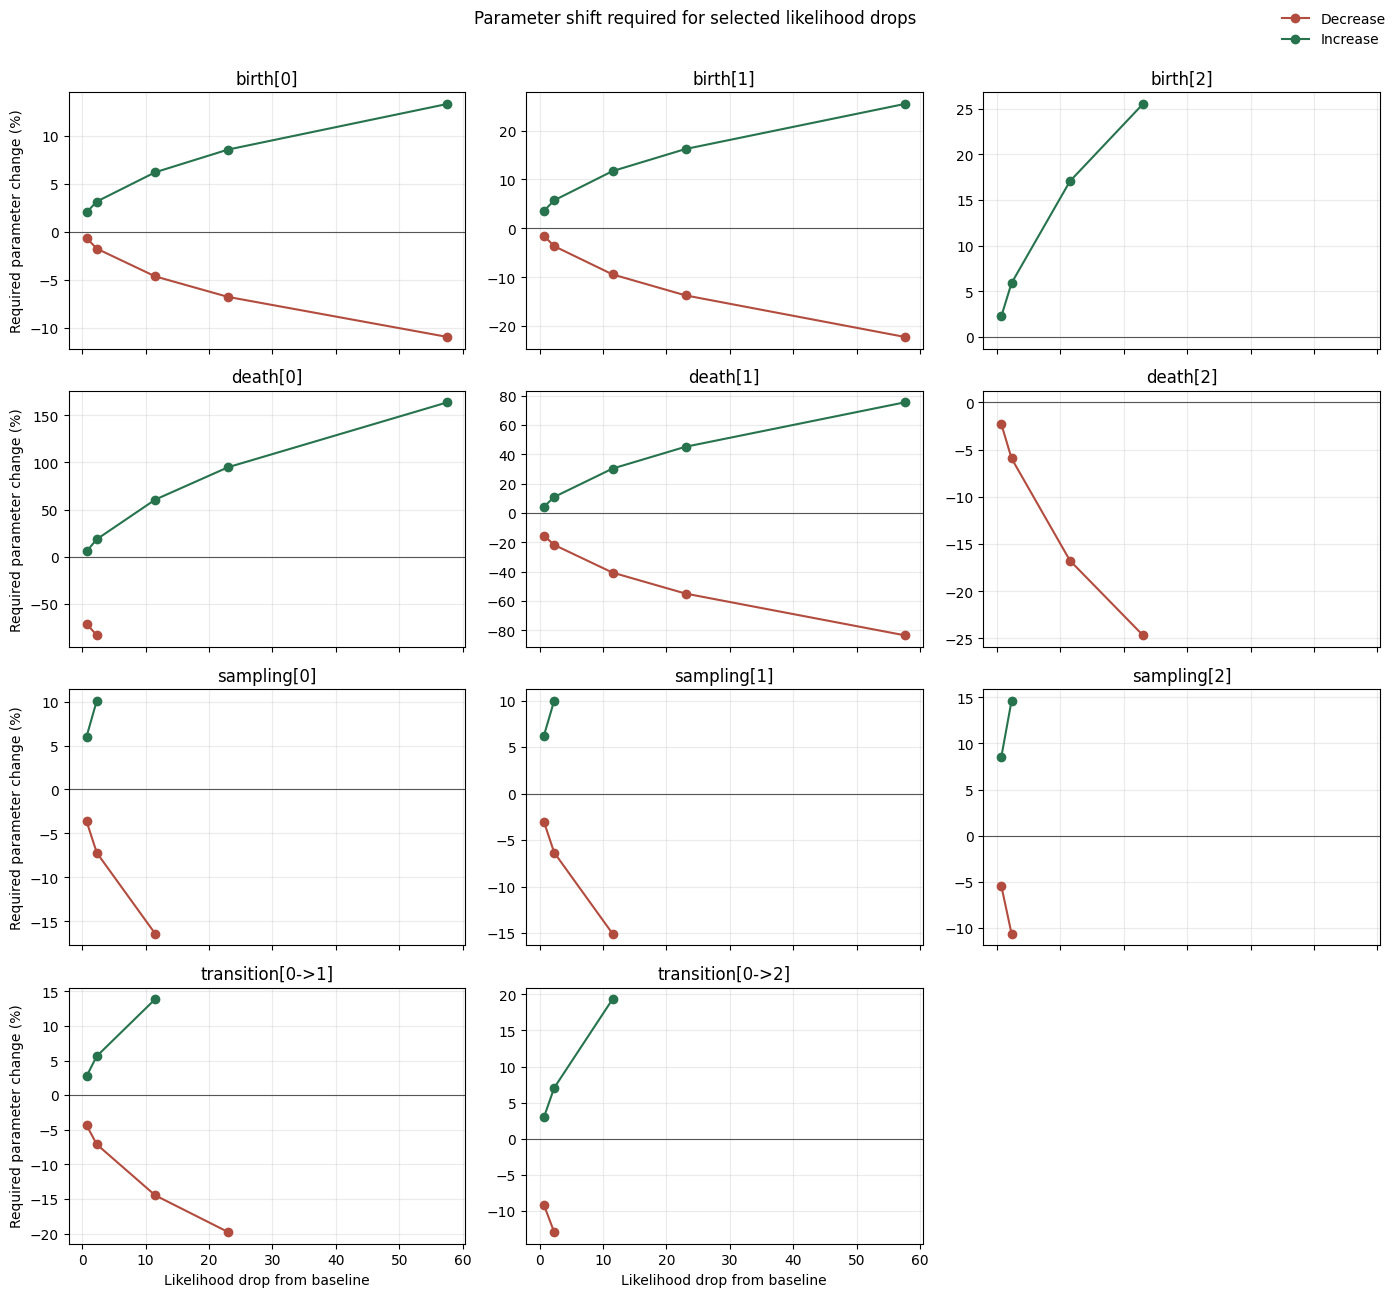

In [27]:
import math


# target_likelihood_drops = [0.5, 1.0, 2.0, 5.0, 10.0]
target_likelihood_drops = ll_drops
parameter_baselines = {}
for parameter_name, parameter_kind, parameter_index, _ in parameter_sweeps:
    if parameter_kind == "birth":
        parameter_baselines[parameter_name] = float(birth_rates[parameter_index])
    elif parameter_kind == "death":
        parameter_baselines[parameter_name] = float(death_rates[parameter_index])
    elif parameter_kind == "sampling":
        parameter_baselines[parameter_name] = float(sampling_probabilities[parameter_index])
    else:
        parameter_baselines[parameter_name] = float(
            transition_probabilities[0, parameter_index]
        )

required_change_rows = []
for parameter_name, _, _, _ in parameter_sweeps:
    baseline_value = parameter_baselines[parameter_name]
    parameter_rows = parameter_sensitivity[
        parameter_sensitivity["parameter"] == parameter_name
    ].sort_values("parameter_value")

    for direction, side_mask, ascending in (
        ("decrease", parameter_rows["parameter_value"] < baseline_value, False),
        ("increase", parameter_rows["parameter_value"] > baseline_value, True),
    ):
        side_rows = parameter_rows.loc[side_mask].sort_values(
            "parameter_value", ascending=ascending
        )
        profile_values = [baseline_value] + side_rows["parameter_value"].tolist()
        profile_changes = [0.0] + side_rows["change_from_baseline"].tolist()

        for likelihood_drop in target_likelihood_drops:
            target_change = -float(likelihood_drop)
            required_value = float("nan")

            for index in range(len(profile_values) - 1):
                value_left = profile_values[index]
                value_right = profile_values[index + 1]
                change_left = profile_changes[index]
                change_right = profile_changes[index + 1]
                crosses_target = (
                    min(change_left, change_right)
                    <= target_change
                    <= max(change_left, change_right)
                )
                if not crosses_target:
                    continue

                if change_left == target_change:
                    required_value = value_left
                elif change_right == target_change:
                    required_value = value_right
                elif change_right != change_left:
                    fraction = (target_change - change_left) / (change_right - change_left)
                    required_value = value_left + fraction * (value_right - value_left)
                break

            parameter_change = required_value - baseline_value
            relative_change_percent = (
                parameter_change / abs(baseline_value) * 100
                if baseline_value != 0 and not math.isnan(required_value)
                else float("nan")
            )
            required_change_rows.append(
                {
                    "parameter": parameter_name,
                    "direction": direction,
                    "likelihood_drop": likelihood_drop,
                    "baseline_value": baseline_value,
                    "required_value": required_value,
                    "parameter_change": parameter_change,
                    "absolute_change": abs(parameter_change),
                    "relative_change_percent": relative_change_percent,
                }
            )

required_parameter_changes = pd.DataFrame(required_change_rows)
print("Required one-at-a-time parameter shifts for likelihood drops from baseline:")
print(
    required_parameter_changes.to_string(
        index=False,
        float_format=lambda value: f"{value:.6g}",
        na_rep="not reached",
    )
)

parameter_order = [sweep[0] for sweep in parameter_sweeps]
plot_columns = 3
plot_rows = math.ceil(len(parameter_order) / plot_columns)
fig, axes = plt.subplots(
    plot_rows,
    plot_columns,
    figsize=(14, 3.2 * plot_rows),
    sharex=True,
    squeeze=False,
)

for parameter_index, parameter_name in enumerate(parameter_order):
    ax = axes.flat[parameter_index]
    parameter_results = required_parameter_changes[
        required_parameter_changes["parameter"] == parameter_name
    ]
    for direction, color in (("decrease", "#b24c3e"), ("increase", "#26734d")):
        direction_results = parameter_results[
            parameter_results["direction"] == direction
        ]
        ax.plot(
            direction_results["likelihood_drop"],
            direction_results["relative_change_percent"],
            marker="o",
            linewidth=1.5,
            color=color,
            label=direction.capitalize(),
        )
    ax.axhline(0, color="#555555", linewidth=0.8)
    ax.set_title(parameter_name)
    ax.grid(alpha=0.25)
    if parameter_index % plot_columns == 0:
        ax.set_ylabel("Required parameter change (%)")
    if parameter_index // plot_columns == plot_rows - 1:
        ax.set_xlabel("Likelihood drop from baseline")

for ax in axes.flat[len(parameter_order):]:
    ax.set_visible(False)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", frameon=False)
fig.suptitle("Parameter shift required for selected likelihood drops", y=1.01)
fig.tight_layout()
plt.show()

,parameter,parameter_type,likelihood_drop,original_value,profile_best_value,lower_parameter_value,higher_parameter_value,lower_maximum_drop_in_domain,higher_maximum_drop_in_domain
0,birth[NMPs],birth,0.693147,7.021004,7.021004,6.988178,7.164334,7369.199379,5365.339790
1,birth[NMPs],birth,2.302585,7.021004,7.021004,6.913278,7.233434,7369.199379,5365.339790
2,birth[NMPs],birth,11.512925,7.021004,7.021004,6.694711,7.454522,7369.199379,5365.339790
3,birth[NMPs],birth,23.025851,7.021004,7.021004,6.546764,7.620811,7369.199379,5365.339790
4,birth[NMPs],birth,57.564627,7.021004,7.021004,6.256584,7.957285,7369.199379,5365.339790
5,birth[Somite],birth,0.693147,4.397460,4.407559,4.342736,4.563534,395.303768,2651.866434
6,birth[Somite],birth,2.302585,4.397460,4.407559,4.236859,4.640877,395.303768,2651.866434
7,birth[Somite],birth,11.512925,4.397460,4.407559,3.986727,4.909199,395.303768,2651.866434
8,birth[Somite],birth,23.025851,4.397460,4.407559,3.794230,5.108062,395.303768,2651.866434
9,birth[Somite],birth,57.564627,4.397460,4.407559,3.422444,5.515599,395.303768,2651.866434


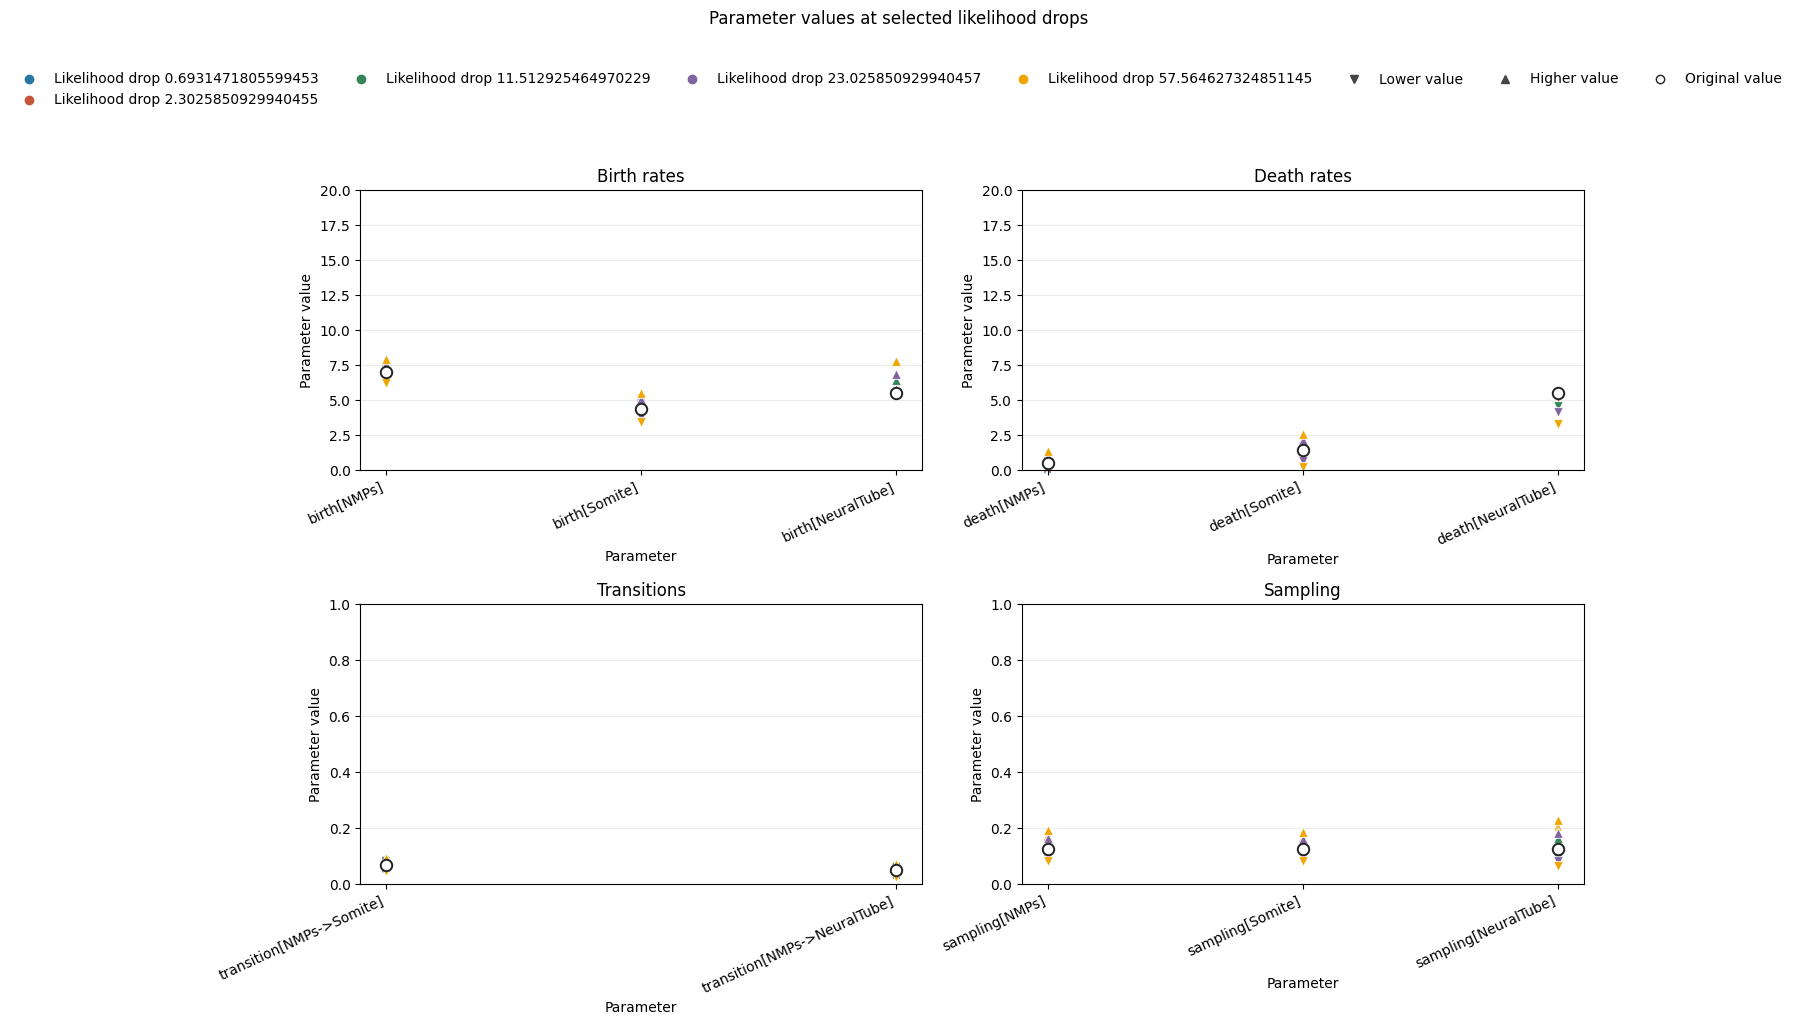

In [28]:
from matplotlib.lines import Line2D

likelihood_drops = ll_drops
drop_colors = {
    ll_drops[0]: "#2878a5",
    ll_drops[1]: "#c4563a",
    ll_drops[2]: "#36845b",
    ll_drops[3]: "#8064a2",
    ll_drops[4]: "#f0a500",
}
state_names = ["NMPs", "Somite", "NeuralTube"]
parameter_labels = {}
parameter_original_values = {}
profile_parameter_rows = []
profile_grid_points = 121
rate_epsilon = 1e-8
probability_epsilon = 1e-8

for parameter_name, parameter_type, parameter_index, _ in parameter_sweeps:
    if parameter_type == "birth":
        original_value = float(birth_rates[parameter_index])
        lower_bound = max(
            rate_epsilon,
            float(death_rates[parameter_index]) + rate_epsilon,
        )
        upper_bound = 20.0
        display_name = f"birth[{state_names[parameter_index]}]"
    elif parameter_type == "death":
        original_value = float(death_rates[parameter_index])
        lower_bound = rate_epsilon
        upper_bound = min(
            20.0,
            float(birth_rates[parameter_index]) - rate_epsilon,
        )
        display_name = f"death[{state_names[parameter_index]}]"
    elif parameter_type == "sampling":
        original_value = float(sampling_probabilities[parameter_index])
        lower_bound = probability_epsilon
        upper_bound = 1.0 - probability_epsilon
        display_name = f"sampling[{state_names[parameter_index]}]"
    else:
        original_value = float(transition_probabilities[0, parameter_index])
        other_outgoing_probability = sum(
            float(transition_probabilities[0, state])
            for state in range(1, num_states)
            if state != parameter_index
        )
        lower_bound = probability_epsilon
        upper_bound = 1.0 - other_outgoing_probability - probability_epsilon
        display_name = (
            f"transition[{state_names[0]}->{state_names[parameter_index]}]"
        )

    if not lower_bound <= original_value <= upper_bound:
        raise ValueError(
            f"Original value for {display_name} is outside the requested valid range"
        )

    parameter_key = (parameter_type, parameter_index)
    parameter_labels[parameter_key] = display_name
    parameter_original_values[parameter_key] = original_value
    parameter_grid = np.unique(
        np.concatenate(
            [
                np.linspace(lower_bound, upper_bound, profile_grid_points),
                [original_value],
            ]
        )
    )

    for candidate_value in parameter_grid:
        trial_birth_rates = birth_rates.clone()
        trial_death_rates = death_rates.clone()
        trial_sampling_probabilities = sampling_probabilities.clone()
        trial_transition_probabilities = transition_probabilities.clone()

        if parameter_type == "birth":
            trial_birth_rates[parameter_index] = candidate_value
        elif parameter_type == "death":
            trial_death_rates[parameter_index] = candidate_value
        elif parameter_type == "sampling":
            trial_sampling_probabilities[parameter_index] = candidate_value
        else:
            trial_transition_probabilities[0, parameter_index] = candidate_value
            trial_transition_probabilities[0, 0] = (
                1.0 - trial_transition_probabilities[0, 1:].sum()
            )

        trial_u_result = calculate_Us(
            birth_rates=trial_birth_rates,
            death_rates=trial_death_rates,
            sampling_probabilities=trial_sampling_probabilities,
            transition_probabilities=trial_transition_probabilities,
            transition_times=torch.tensor(transition_times, dtype=torch.float64),
            root_times=root_times,
        )

        total_loglikelihood = 0.0
        for applicable_transition_times, datastructure in sensitivity_inputs:
            likelihood_by_root_state = calculate_log_likelihood(
                datastructure=datastructure,
                birth_rates=trial_birth_rates,
                death_rates=trial_death_rates,
                transition_probabilities=trial_transition_probabilities,
                sampling_probabilities=trial_sampling_probabilities,
                Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
                transition_times=applicable_transition_times,
            )
            total_loglikelihood += float(likelihood_by_root_state[0, 0])

        profile_parameter_rows.append(
            {
                "parameter": display_name,
                "parameter_type": parameter_type,
                "parameter_value": float(candidate_value),
                "summed_log_likelihood": total_loglikelihood,
            }
        )

full_parameter_sensitivity = pd.DataFrame(profile_parameter_rows)


def threshold_parameter_value(parameter_values, likelihood_drops, target_drop):
    best_index = int(np.argmin(likelihood_drops))
    lower_values = parameter_values[:best_index + 1][::-1]
    lower_drops = likelihood_drops[:best_index + 1][::-1]
    higher_values = parameter_values[best_index:]
    higher_drops = likelihood_drops[best_index:]

    results = []
    for side_values, side_drops in (
        (lower_values, lower_drops),
        (higher_values, higher_drops),
    ):
        maximum_drop = float(np.max(side_drops))
        required_value = np.nan
        for index in range(len(side_values) - 1):
            drop_start = side_drops[index]
            drop_end = side_drops[index + 1]
            if min(drop_start, drop_end) <= target_drop <= max(drop_start, drop_end):
                if drop_end == drop_start:
                    required_value = float(side_values[index])
                else:
                    fraction = (target_drop - drop_start) / (drop_end - drop_start)
                    required_value = float(
                        side_values[index]
                        + fraction * (side_values[index + 1] - side_values[index])
                    )
                break
        results.append((required_value, maximum_drop))

    return results


rows = []
for (parameter_type, parameter_index), original_value in parameter_original_values.items():
    parameter_name = parameter_labels[(parameter_type, parameter_index)]
    profile_rows = full_parameter_sensitivity[
        full_parameter_sensitivity["parameter"] == parameter_name
    ].sort_values("parameter_value")
    parameter_values = profile_rows["parameter_value"].to_numpy()
    likelihood_drops_from_baseline = (
        baseline_ll - profile_rows["summed_log_likelihood"].to_numpy()
    )
    best_value = float(parameter_values[np.argmin(likelihood_drops_from_baseline)])

    for target_drop in likelihood_drops:
        (lower_result, higher_result) = threshold_parameter_value(
            parameter_values,
            likelihood_drops_from_baseline,
            target_drop,
        )
        lower_value, lower_maximum_drop = lower_result
        higher_value, higher_maximum_drop = higher_result
        rows.append(
            {
                "parameter": parameter_name,
                "parameter_type": parameter_type,
                "likelihood_drop": target_drop,
                "original_value": original_value,
                "profile_best_value": best_value,
                "lower_parameter_value": lower_value,
                "higher_parameter_value": higher_value,
                "lower_maximum_drop_in_domain": lower_maximum_drop,
                "higher_maximum_drop_in_domain": higher_maximum_drop,
            }
        )

parameter_value_ranges = pd.DataFrame(rows)
display(parameter_value_ranges)

parameter_families = [
    ("Birth rates", "birth", (0, 20)),
    ("Death rates", "death", (0, 20)),
    ("Transitions", "transition", (0, 1)),
    ("Sampling", "sampling", (0, 1)),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10), squeeze=False)

for ax, (family_title, parameter_type, value_limits) in zip(axes.flat, parameter_families):
    parameter_entries = [
        (key, label)
        for key, label in parameter_labels.items()
        if key[0] == parameter_type
    ]

    for parameter_position, (parameter_key, parameter_name) in enumerate(parameter_entries):
        parameter_rows = parameter_value_ranges[
            parameter_value_ranges["parameter"] == parameter_name
        ].set_index("likelihood_drop")

        for target_drop in likelihood_drops:
            result = parameter_rows.loc[target_drop]
            lower_value = result["lower_parameter_value"]
            higher_value = result["higher_parameter_value"]
            color = drop_colors[target_drop]

            if np.isfinite(lower_value) and np.isfinite(higher_value):
                ax.annotate(
                    "",
                    xy=(parameter_position, higher_value),
                    xytext=(parameter_position, lower_value),
                    arrowprops={
                        "arrowstyle": "<->",
                        "color": color,
                        "linewidth": 1.2,
                        "alpha": 0.7,
                    },
                    zorder=1,
                )
            if np.isfinite(lower_value):
                ax.scatter(
                    parameter_position,
                    lower_value,
                    color=color,
                    marker="v",
                    edgecolor="white",
                    linewidth=0.6,
                    s=48,
                    zorder=2,
                )
            if np.isfinite(higher_value):
                ax.scatter(
                    parameter_position,
                    higher_value,
                    color=color,
                    marker="^",
                    edgecolor="white",
                    linewidth=0.6,
                    s=48,
                    zorder=2,
                )

        ax.scatter(
            parameter_position,
            parameter_original_values[parameter_key],
            color="white",
            edgecolor="#222222",
            linewidth=1.4,
            marker="o",
            s=68,
            zorder=4,
        )

    ax.set_title(family_title)
    ax.set_xticks(np.arange(len(parameter_entries)))
    ax.set_xticklabels([label for _, label in parameter_entries], rotation=25, ha="right")
    ax.set_xlabel("Parameter")
    ax.set_ylabel("Parameter value")
    ax.set_ylim(value_limits)
    ax.grid(axis="y", alpha=0.25)

legend_handles = [
    Line2D([], [], color=color, marker="o", linestyle="None", label=f"Likelihood drop {drop}")
    for drop, color in drop_colors.items()
]
legend_handles.extend(
    [
        Line2D([], [], color="#444444", marker="v", linestyle="None", label="Lower value"),
        Line2D([], [], color="#444444", marker="^", linestyle="None", label="Higher value"),
        Line2D([], [], color="#222222", marker="o", markerfacecolor="white", linestyle="None", label="Original value"),
    ]
)
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=7,
    frameon=False,
)
fig.suptitle("Parameter values at selected likelihood drops", y=1.02)
fig.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

In [33]:
unreachable_endpoint_rows = []
for _, result in parameter_value_ranges.iterrows():
    for direction, value_column, maximum_column in (
        ("Lower", "lower_parameter_value", "lower_maximum_drop_in_domain"),
        ("Higher", "higher_parameter_value", "higher_maximum_drop_in_domain"),
    ):
        if not np.isfinite(result[value_column]):
            unreachable_endpoint_rows.append(
                {
                    "parameter": result["parameter"],
                    "likelihood_drop": result["likelihood_drop"],
                    "direction": direction,
                    "maximum_drop_in_valid_domain": result[maximum_column],
                }
            )

unreachable_endpoints = pd.DataFrame(unreachable_endpoint_rows)
if unreachable_endpoints.empty:
    print("All requested likelihood-drop endpoints were reached.")
else:
    print("These endpoints are not reachable within the valid parameter domains:")
    display(unreachable_endpoints)

KeyError: 'likelihood_drop'

In [34]:
from pathlib import Path

# --------------------------------------------------
# Create output directory
# --------------------------------------------------

output_dir = Path(f"../data/troupe/figures/{DATASET}")
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Build parameter_value_ranges
# (everything up to the point where parameter_value_ranges
# is created in your current notebook)
# --------------------------------------------------

# likelihood_fractions = [0.9, 0.5, 0.1]
target_drops = ll_drops

state_names = ["NMPs", "Somite", "NeuralTube"]
parameter_labels = {}
parameter_original_values = {}
profile_parameter_rows = []

profile_grid_points = 121
rate_epsilon = 1e-8
probability_epsilon = 1e-8

for parameter_name, parameter_type, parameter_index, _ in parameter_sweeps:

    if parameter_type == "birth":
        original_value = float(birth_rates[parameter_index])
        lower_bound = max(
            rate_epsilon,
            float(death_rates[parameter_index]) + rate_epsilon,
        )
        upper_bound = 20.0
        display_name = f"birth[{state_names[parameter_index]}]"

    elif parameter_type == "death":
        original_value = float(death_rates[parameter_index])
        lower_bound = rate_epsilon
        upper_bound = min(
            20.0,
            float(birth_rates[parameter_index]) - rate_epsilon,
        )
        display_name = f"death[{state_names[parameter_index]}]"

    elif parameter_type == "sampling":
        original_value = float(sampling_probabilities[parameter_index])
        lower_bound = probability_epsilon
        upper_bound = 1.0 - probability_epsilon
        display_name = f"sampling[{state_names[parameter_index]}]"

    else:
        original_value = float(transition_probabilities[0, parameter_index])

        other_outgoing_probability = sum(
            float(transition_probabilities[0, state])
            for state in range(1, num_states)
            if state != parameter_index
        )

        lower_bound = probability_epsilon
        upper_bound = 1.0 - other_outgoing_probability - probability_epsilon

        display_name = (
            f"transition[{state_names[0]}->{state_names[parameter_index]}]"
        )

    parameter_key = (parameter_type, parameter_index)

    parameter_labels[parameter_key] = display_name
    parameter_original_values[parameter_key] = original_value

    parameter_grid = np.unique(
        np.concatenate(
            [
                np.linspace(lower_bound, upper_bound, profile_grid_points),
                [original_value],
            ]
        )
    )

    for candidate_value in parameter_grid:

        trial_birth_rates = birth_rates.clone()
        trial_death_rates = death_rates.clone()
        trial_sampling_probabilities = sampling_probabilities.clone()
        trial_transition_probabilities = transition_probabilities.clone()

        if parameter_type == "birth":
            trial_birth_rates[parameter_index] = candidate_value

        elif parameter_type == "death":
            trial_death_rates[parameter_index] = candidate_value

        elif parameter_type == "sampling":
            trial_sampling_probabilities[parameter_index] = candidate_value

        else:
            trial_transition_probabilities[0, parameter_index] = candidate_value
            trial_transition_probabilities[0, 0] = (
                1.0 - trial_transition_probabilities[0, 1:].sum()
            )

        trial_u_result = calculate_Us(
            birth_rates=trial_birth_rates,
            death_rates=trial_death_rates,
            sampling_probabilities=trial_sampling_probabilities,
            transition_probabilities=trial_transition_probabilities,
            transition_times=torch.tensor(
                transition_times,
                dtype=torch.float64,
            ),
            root_times=root_times,
        )

        total_loglikelihood = 0.0

        for applicable_transition_times, datastructure in sensitivity_inputs:

            likelihood_by_root_state = calculate_log_likelihood(
                datastructure=datastructure,
                birth_rates=trial_birth_rates,
                death_rates=trial_death_rates,
                transition_probabilities=trial_transition_probabilities,
                sampling_probabilities=trial_sampling_probabilities,
                Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
                transition_times=applicable_transition_times,
            )

            total_loglikelihood += float(
                likelihood_by_root_state[0, 0]
            )

        profile_parameter_rows.append(
            {
                "parameter": display_name,
                "parameter_type": parameter_type,
                "parameter_value": float(candidate_value),
                "summed_log_likelihood": total_loglikelihood,
            }
        )

full_parameter_sensitivity = pd.DataFrame(profile_parameter_rows)

# --------------------------------------------------
# Same helper from your notebook
# --------------------------------------------------

def threshold_parameter_value(parameter_values, likelihood_drops, target_drop):

    best_index = int(np.argmin(likelihood_drops))

    lower_values = parameter_values[: best_index + 1][::-1]
    lower_drops = likelihood_drops[: best_index + 1][::-1]

    higher_values = parameter_values[best_index:]
    higher_drops = likelihood_drops[best_index:]

    def interpolate(values, drops):

        max_drop = np.max(drops)

        if max_drop < target_drop:
            return np.nan, max_drop

        for i in range(len(values) - 1):

            d1 = drops[i]
            d2 = drops[i + 1]

            if (d1 <= target_drop <= d2) or (d2 <= target_drop <= d1):

                if d1 == d2:
                    return values[i], max_drop

                frac = (target_drop - d1) / (d2 - d1)

                return (
                    values[i] + frac * (values[i + 1] - values[i]),
                    max_drop,
                )

        return np.nan, max_drop

    return (
        interpolate(lower_values, lower_drops),
        interpolate(higher_values, higher_drops),
    )

rows = []

for parameter_name in full_parameter_sensitivity["parameter"].unique():

    parameter_rows = (
        full_parameter_sensitivity[
            full_parameter_sensitivity["parameter"] == parameter_name
        ]
        .sort_values("parameter_value")
        .reset_index(drop=True)
    )

    parameter_type = parameter_rows["parameter_type"].iloc[0]

    original_value = next(
        v
        for k, v in parameter_original_values.items()
        if parameter_labels[k] == parameter_name
    )

    parameter_values = parameter_rows["parameter_value"].to_numpy()

    original_log_likelihood = parameter_rows.loc[
        np.isclose(parameter_rows["parameter_value"], original_value),
        "summed_log_likelihood",
    ].iloc[0]
    likelihood_drops_from_baseline = (
        original_log_likelihood
        - parameter_rows["summed_log_likelihood"].to_numpy()
    )

    best_value = float(
        parameter_values[np.argmin(likelihood_drops_from_baseline)]
    )

    for alpha, target_drop in zip(alphas, target_drops):

        lower_result, higher_result = threshold_parameter_value(
            parameter_values,
            likelihood_drops_from_baseline,
            target_drop,
        )

        lower_value, lower_maximum_drop = lower_result
        higher_value, higher_maximum_drop = higher_result

        rows.append(
            {
                "parameter": parameter_name,
                "parameter_type": parameter_type,
                "likelihood_fraction": alpha,
                "original_value": original_value,
                "profile_best_value": best_value,
                "lower_parameter_value": lower_value,
                "higher_parameter_value": higher_value,
                "lower_maximum_drop_in_domain": lower_maximum_drop,
                "higher_maximum_drop_in_domain": higher_maximum_drop,
            }
        )

parameter_value_ranges = pd.DataFrame(rows)

# --------------------------------------------------
# Save everything needed for plotting
# --------------------------------------------------

parameter_value_ranges.to_csv(
    output_dir / "parameter_value_ranges.csv",
    index=False,
)

pd.DataFrame(
    [
        {
            "parameter_type": k[0],
            "parameter_index": k[1],
            "parameter": parameter_labels[k],
            "original_value": parameter_original_values[k],
        }
        for k in parameter_labels
    ]
).to_csv(
    output_dir / "parameter_metadata.csv",
    index=False,
)

print("Saved:")
print(output_dir / "parameter_value_ranges.csv")
print(output_dir / "parameter_metadata.csv")

Saved:
../data/troupe/figures/TLSC/parameter_value_ranges.csv
../data/troupe/figures/TLSC/parameter_metadata.csv


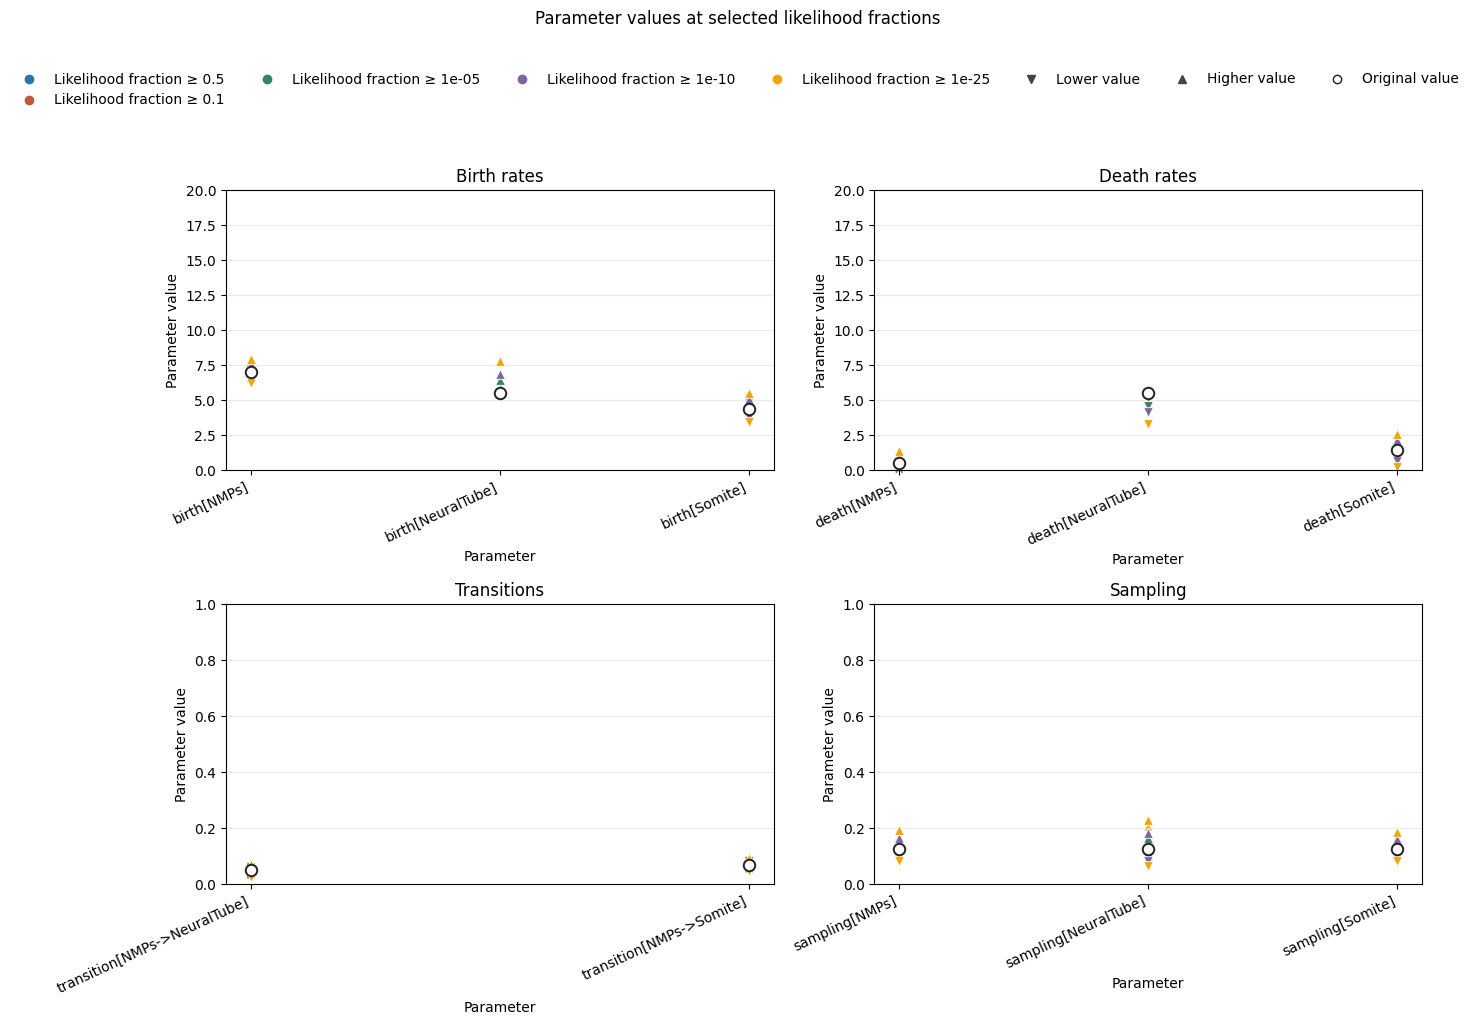

In [35]:
from matplotlib.lines import Line2D
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

output_dir = Path(f"../data/troupe/figures/{DATASET}")

parameter_value_ranges = pd.read_csv(
    output_dir / "parameter_value_ranges.csv"
)

parameter_metadata = pd.read_csv(
    output_dir / "parameter_metadata.csv"
)

likelihood_fractions = alphas

fraction_colors = {
    alphas[0]: "#2878a5",
    alphas[1]: "#c4563a",
    alphas[2]: "#36845b",
    alphas[3]: "#8064a2",
    alphas[4]: "#f0a500",
}

parameter_families = [
    ("Birth rates", "birth", (0, 20)),
    ("Death rates", "death", (0, 20)),
    ("Transitions", "transition", (0, 1)),
    ("Sampling", "sampling", (0, 1)),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    squeeze=False,
)

for ax, (family_title, parameter_type, value_limits) in zip(
    axes.flat,
    parameter_families,
):

    family_parameters = (
        parameter_metadata[
            parameter_metadata["parameter_type"] == parameter_type
        ]
        .sort_values("parameter")
        .reset_index(drop=True)
    )

    for parameter_position, (_, meta_row) in enumerate(
        family_parameters.iterrows()
    ):

        parameter_name = meta_row["parameter"]
        original_value = meta_row["original_value"]

        parameter_rows = (
            parameter_value_ranges[
                parameter_value_ranges["parameter"] == parameter_name
            ]
            .set_index("likelihood_fraction")
        )
        fraction_index = parameter_rows.index.to_numpy(dtype=float)

        for alpha in likelihood_fractions:

            matches = np.flatnonzero(
                np.isclose(fraction_index, alpha, rtol=1e-12, atol=0.0)
            )
            if matches.size != 1:
                raise KeyError(
                    f"Expected one row for likelihood fraction {alpha}; "
                    f"found {matches.size} in {fraction_index.tolist()}"
                )
            result = parameter_rows.iloc[matches[0]]

            lower_value = result["lower_parameter_value"]
            higher_value = result["higher_parameter_value"]

            color = fraction_colors[alpha]

            if np.isfinite(lower_value) and np.isfinite(higher_value):

                ax.annotate(
                    "",
                    xy=(parameter_position, higher_value),
                    xytext=(parameter_position, lower_value),
                    arrowprops=dict(
                        arrowstyle="<->",
                        color=color,
                        linewidth=1.2,
                        alpha=0.7,
                    ),
                    zorder=1,
                )

            if np.isfinite(lower_value):
                ax.scatter(
                    parameter_position,
                    lower_value,
                    color=color,
                    marker="v",
                    edgecolor="white",
                    linewidth=0.6,
                    s=48,
                    zorder=2,
                )

            if np.isfinite(higher_value):
                ax.scatter(
                    parameter_position,
                    higher_value,
                    color=color,
                    marker="^",
                    edgecolor="white",
                    linewidth=0.6,
                    s=48,
                    zorder=2,
                )

        ax.scatter(
            parameter_position,
            original_value,
            color="white",
            edgecolor="#222222",
            linewidth=1.4,
            marker="o",
            s=68,
            zorder=4,
        )

    ax.set_title(family_title)

    ax.set_xticks(np.arange(len(family_parameters)))
    ax.set_xticklabels(
        family_parameters["parameter"],
        rotation=25,
        ha="right",
    )

    ax.set_xlabel("Parameter")
    ax.set_ylabel("Parameter value")
    ax.set_ylim(value_limits)
    ax.grid(axis="y", alpha=0.25)

legend_handles = [
    Line2D(
        [],
        [],
        color=color,
        marker="o",
        linestyle="None",
        label=f"Likelihood fraction ≥ {alpha:g}",
    )
    for alpha, color in fraction_colors.items()
]

legend_handles.extend(
    [
        Line2D(
            [],
            [],
            color="#444444",
            marker="v",
            linestyle="None",
            label="Lower value",
        ),
        Line2D(
            [],
            [],
            color="#444444",
            marker="^",
            linestyle="None",
            label="Higher value",
        ),
        Line2D(
            [],
            [],
            color="#222222",
            marker="o",
            markerfacecolor="white",
            linestyle="None",
            label="Original value",
        ),
    ]
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=7,
    frameon=False,
)

fig.suptitle(
    "Parameter values at selected likelihood fractions",
    y=1.02,
)

fig.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

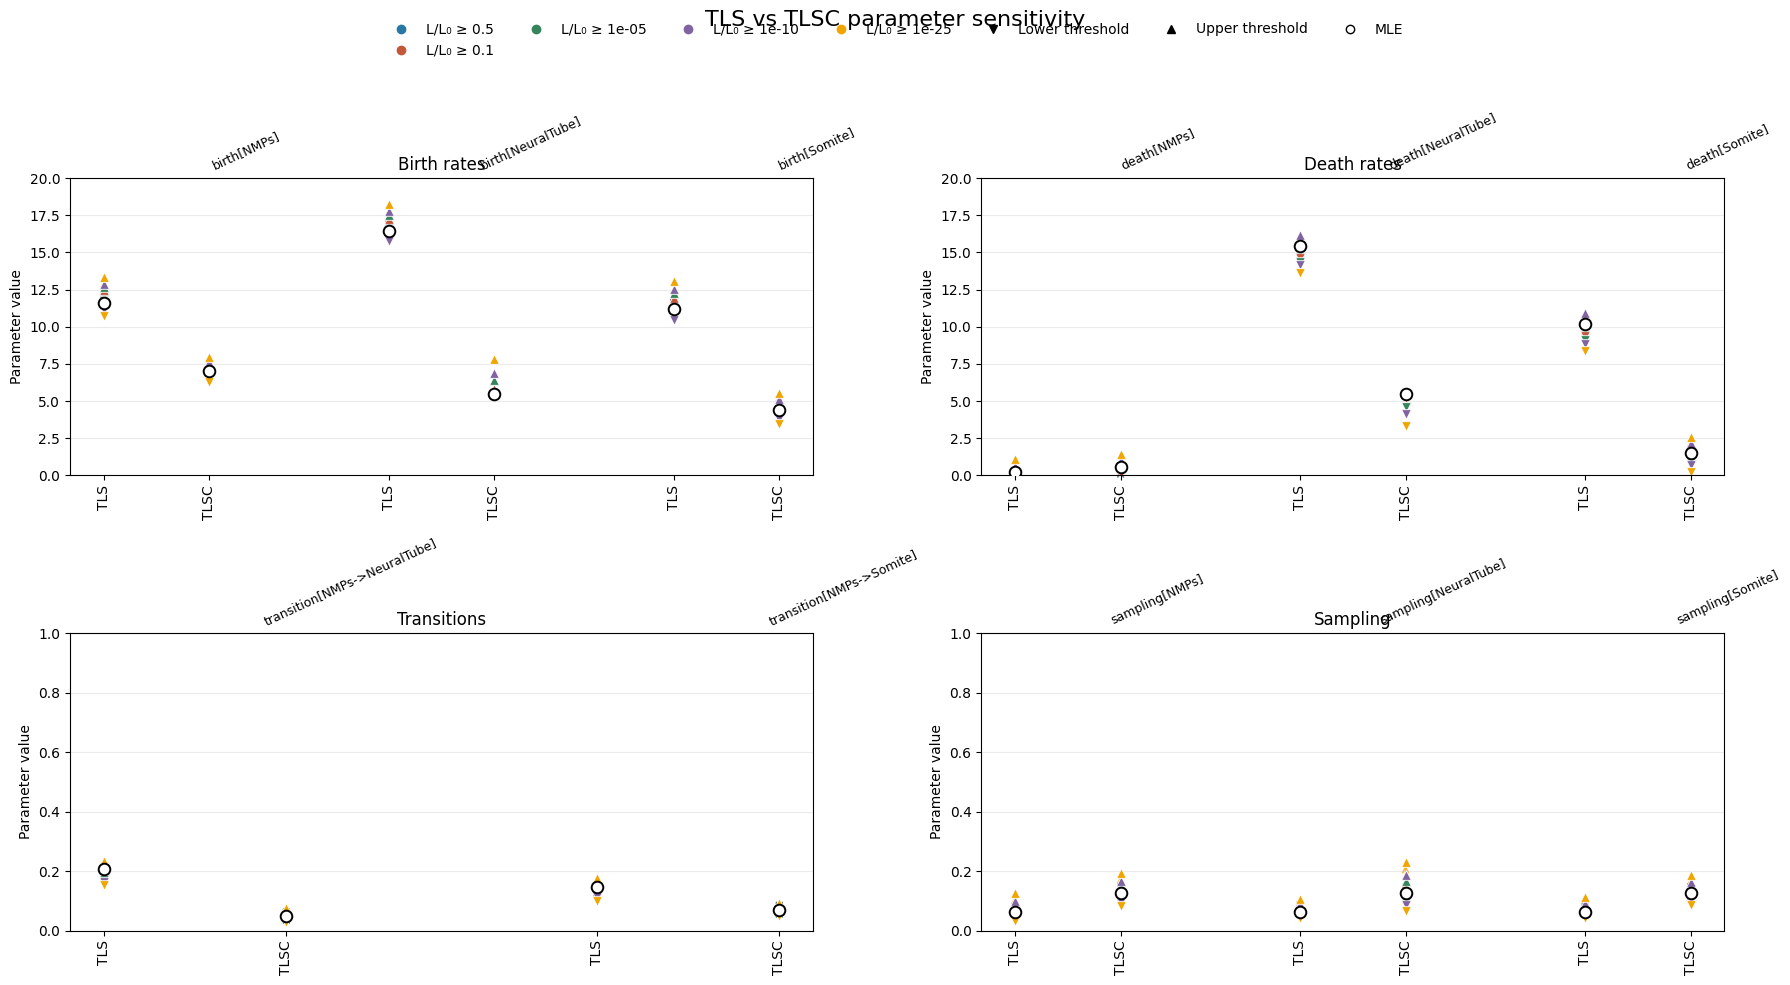

In [36]:
from pathlib import Path
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["TLS", "TLSC"]

likelihood_fractions = alphas

fraction_colors = {
    alphas[0]: "#2878a5",
    alphas[1]: "#c4563a",
    alphas[2]: "#36845b",
    alphas[3]: "#8064a2",
    alphas[4]: "#f0a500",
}

parameter_families = [
    ("Birth rates", "birth", (0, 20)),
    ("Death rates", "death", (0, 20)),
    ("Transitions", "transition", (0, 1)),
    ("Sampling", "sampling", (0, 1)),
]

# --------------------------------------------------
# Load both datasets
# --------------------------------------------------

all_ranges = {}
all_metadata = {}

for dataset in DATASETS:

    output_dir = Path(f"../data/troupe/figures/{dataset}")

    all_ranges[dataset] = pd.read_csv(
        output_dir / "parameter_value_ranges.csv"
    )

    all_metadata[dataset] = pd.read_csv(
        output_dir / "parameter_metadata.csv"
    )

# --------------------------------------------------
# Figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 10),
    squeeze=False,
)

for ax, (family_title, parameter_type, value_limits) in zip(
    axes.flat,
    parameter_families,
):

    reference_metadata = (
        all_metadata["TLS"]
        .query("parameter_type == @parameter_type")
        .sort_values("parameter")
        .reset_index(drop=True)
    )

    xticks = []
    xticklabels = []

    current_x = 0

    for _, meta_row in reference_metadata.iterrows():

        parameter_name = meta_row["parameter"]

        for dataset in DATASETS:

            x = current_x

            ranges_df = all_ranges[dataset]
            metadata_df = all_metadata[dataset]

            parameter_rows = (
                ranges_df[
                    ranges_df["parameter"] == parameter_name
                ]
                .set_index("likelihood_fraction")
            )
            fraction_index = parameter_rows.index.to_numpy(dtype=float)

            original_value = (
                metadata_df[
                    metadata_df["parameter"] == parameter_name
                ]["original_value"]
                .iloc[0]
            )

            for alpha in likelihood_fractions:

                matches = np.flatnonzero(
                    np.isclose(fraction_index, alpha, rtol=1e-12, atol=0.0)
                )
                if matches.size != 1:
                    raise KeyError(
                        f"Expected one row for likelihood fraction {alpha}; "
                        f"found {matches.size} in {fraction_index.tolist()}"
                    )
                result = parameter_rows.iloc[matches[0]]

                lower_value = result["lower_parameter_value"]
                higher_value = result["higher_parameter_value"]

                color = fraction_colors[alpha]

                if (
                    np.isfinite(lower_value)
                    and np.isfinite(higher_value)
                ):

                    ax.annotate(
                        "",
                        xy=(x, higher_value),
                        xytext=(x, lower_value),
                        arrowprops=dict(
                            arrowstyle="<->",
                            color=color,
                            linewidth=1.2,
                            alpha=0.7,
                        ),
                        zorder=1,
                    )

                if np.isfinite(lower_value):
                    ax.scatter(
                        x,
                        lower_value,
                        color=color,
                        marker="v",
                        edgecolor="white",
                        linewidth=0.6,
                        s=48,
                        zorder=2,
                    )

                if np.isfinite(higher_value):
                    ax.scatter(
                        x,
                        higher_value,
                        color=color,
                        marker="^",
                        edgecolor="white",
                        linewidth=0.6,
                        s=48,
                        zorder=2,
                    )

            ax.scatter(
                x,
                original_value,
                color="white",
                edgecolor="black",
                linewidth=1.4,
                marker="o",
                s=70,
                zorder=4,
            )

            xticks.append(x)
            xticklabels.append(dataset)

            current_x += 1

        # gap between parameter groups
        current_x += 0.7

        # parameter label above pair
        center_x = current_x - 1.35

        ax.text(
            center_x,
            value_limits[1] * 1.02,
            parameter_name,
            rotation=25,
            ha="center",
            va="bottom",
            fontsize=9,
        )

    ax.set_title(family_title)

    ax.set_xticks(xticks)
    ax.set_xticklabels(
        xticklabels,
        rotation=90,
    )

    ax.set_ylabel("Parameter value")
    ax.set_ylim(value_limits)

    ax.grid(axis="y", alpha=0.25)

# --------------------------------------------------
# Legend
# --------------------------------------------------

legend_handles = [
    Line2D(
        [],
        [],
        color=color,
        marker="o",
        linestyle="None",
        label=f"L/L₀ ≥ {alpha:g}",
    )
    for alpha, color in fraction_colors.items()
]

legend_handles.extend(
    [
        Line2D(
            [],
            [],
            color="black",
            marker="v",
            linestyle="None",
            label="Lower threshold",
        ),
        Line2D(
            [],
            [],
            color="black",
            marker="^",
            linestyle="None",
            label="Upper threshold",
        ),
        Line2D(
            [],
            [],
            color="black",
            marker="o",
            markerfacecolor="white",
            linestyle="None",
            label="MLE",
        ),
    ]
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=7,
    frameon=False,
)

fig.suptitle(
    "TLS vs TLSC parameter sensitivity",
    fontsize=16,
)

fig.tight_layout(rect=(0, 0, 1, 0.93))

plt.show()

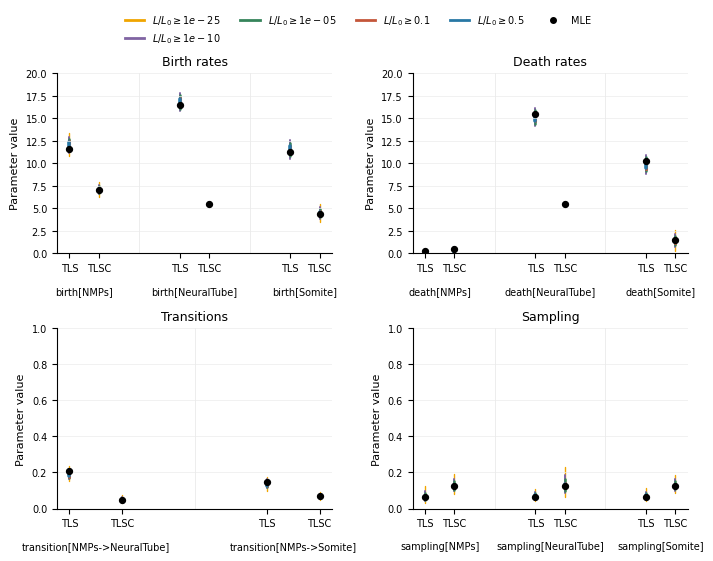

In [37]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --------------------------------------------------
# Nature-like style
# --------------------------------------------------

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

DATASETS = ["TLS", "TLSC"]

fraction_order = sorted(alphas)

fraction_colors = {
    alphas[0]: "#2878a5",
    alphas[1]: "#c4563a",
    alphas[2]: "#36845b",
    alphas[3]: "#8064a2",
    alphas[4]: "#f0a500",
}

parameter_families = [
    ("Birth rates", "birth", (0, 20)),
    ("Death rates", "death", (0, 20)),
    ("Transitions", "transition", (0, 1)),
    ("Sampling", "sampling", (0, 1)),
]

# --------------------------------------------------
# load data
# --------------------------------------------------

all_ranges = {}
all_metadata = {}

for dataset in DATASETS:

    base = Path(f"../data/troupe/figures/{dataset}")

    all_ranges[dataset] = pd.read_csv(
        base / "parameter_value_ranges.csv"
    )

    all_metadata[dataset] = pd.read_csv(
        base / "parameter_metadata.csv"
    )

# --------------------------------------------------
# figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(7.2, 5.5),
)

axes = axes.flatten()

for ax, (title, parameter_type, ylim) in zip(
    axes,
    parameter_families,
):

    parameters = (
        all_metadata["TLS"]
        .query("parameter_type == @parameter_type")
        .sort_values("parameter")
        .reset_index(drop=True)
    )

    xticks = []
    xticklabels = []

    group_spacing = 3.0
    within_spacing = 0.8

    for p_idx, (_, row) in enumerate(parameters.iterrows()):

        parameter = row["parameter"]

        x_tls = p_idx * group_spacing
        x_tlsc = x_tls + within_spacing

        for x, dataset in zip(
            [x_tls, x_tlsc],
            DATASETS,
        ):

            ranges = all_ranges[dataset]
            meta = all_metadata[dataset]

            param_rows = (
                ranges[ranges["parameter"] == parameter]
                .set_index("likelihood_fraction")
            )
            fraction_index = param_rows.index.to_numpy(dtype=float)

            mle = (
                meta[meta["parameter"] == parameter]
                ["original_value"]
                .iloc[0]
            )

            for linewidth, alpha in zip(
                [1.0, 1.4, 1.8, 2.2, 2.6],
                fraction_order,
            ):

                matches = np.flatnonzero(
                    np.isclose(fraction_index, alpha, rtol=1e-12, atol=0.0)
                )
                if matches.size != 1:
                    raise KeyError(
                        f"Expected one row for likelihood fraction {alpha}; "
                        f"found {matches.size} in {fraction_index.tolist()}"
                    )
                r = param_rows.iloc[matches[0]]

                low = r["lower_parameter_value"]
                high = r["higher_parameter_value"]

                if (
                    np.isfinite(low)
                    and np.isfinite(high)
                ):

                    ax.plot(
                        [x, x],
                        [low, high],
                        color=fraction_colors[alpha],
                        linewidth=linewidth,
                        solid_capstyle="round",
                        zorder=1,
                    )

            ax.scatter(
                x,
                mle,
                s=18,
                color="black",
                zorder=3,
            )

        xticks.extend([x_tls, x_tlsc])
        xticklabels.extend(["TLS", "TLSC"])

        center = (x_tls + x_tlsc) / 2

        ax.text(
            center,
            -0.18,
            parameter,
            ha="center",
            va="top",
            fontsize=7,
            transform=ax.get_xaxis_transform(),
        )

    # separators

    for p_idx in range(len(parameters) - 1):

        sep = (
            p_idx * group_spacing
            + within_spacing
            + (group_spacing - within_spacing) / 2
        )

        ax.axvline(
            sep,
            color="0.9",
            linewidth=0.5,
            zorder=0,
        )

    ax.set_title(title)

    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)

    ax.set_ylim(*ylim)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        color="0.92",
        linewidth=0.5,
    )

    ax.set_ylabel("Parameter value")

# --------------------------------------------------
# legend
# --------------------------------------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        color=fraction_colors[alpha],
        lw=2,
        label=rf"$L/L_0 \geq {alpha:g}$",
    )
    for alpha in fraction_order
]

legend_elements.append(
    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        linestyle="",
        markersize=4,
        label="MLE",
    )
)

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "../data/troupe/figures/TLS_vs_TLSC_sensitivity.pdf",
    bbox_inches="tight",
)

plt.savefig(
    "../data/troupe/figures/TLS_vs_TLSC_sensitivity.svg",
    bbox_inches="tight",
)

plt.show()

In [ ]:
# --------------------------------------------------
# Create growth-rate entries (birth - death)
# --------------------------------------------------



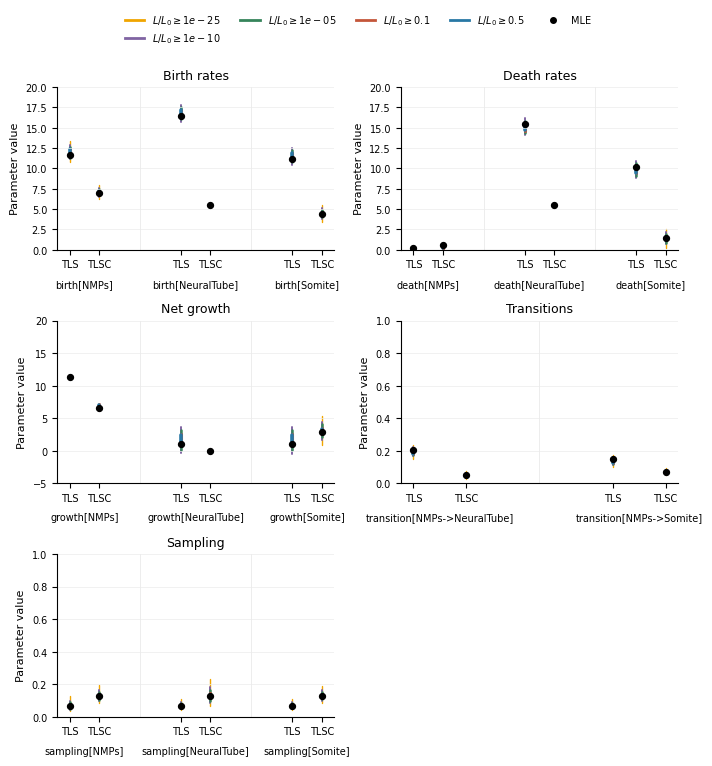

In [38]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --------------------------------------------------
# Nature-like style
# --------------------------------------------------

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

DATASETS = ["TLS", "TLSC"]

fraction_order = sorted(alphas)

fraction_colors = {
    alphas[0]: "#2878a5",
    alphas[1]: "#c4563a",
    alphas[2]: "#36845b",
    alphas[3]: "#8064a2",
    alphas[4]: "#f0a500",
}

parameter_families = [
    ("Birth rates", "birth", (0, 20)),
    ("Death rates", "death", (0, 20)),
    ("Net growth", "growth", (-5, 20)),
    ("Transitions", "transition", (0, 1)),
    ("Sampling", "sampling", (0, 1)),
]

# --------------------------------------------------
# load data
# --------------------------------------------------

all_ranges = {}
all_metadata = {}

for dataset in DATASETS:

    base = Path(f"../data/troupe/figures/{dataset}")

    all_ranges[dataset] = pd.read_csv(
        base / "parameter_value_ranges.csv"
    )

    all_metadata[dataset] = pd.read_csv(
        base / "parameter_metadata.csv"
    )

    ranges_df = all_ranges[dataset]
    metadata_df = all_metadata[dataset]

    growth_rows = []
    growth_metadata = []

    birth_meta = metadata_df[
        metadata_df["parameter_type"] == "birth"
    ].copy()

    death_meta = metadata_df[
        metadata_df["parameter_type"] == "death"
    ].copy()

    state_names = []

    for _, birth_row in birth_meta.iterrows():

        state = birth_row["parameter"].replace(
            "birth[", ""
        ).replace("]", "")

        state_names.append(state)

    for state in state_names:

        birth_name = f"birth[{state}]"
        death_name = f"death[{state}]"

        birth_original = metadata_df.loc[
            metadata_df["parameter"] == birth_name,
            "original_value",
        ].iloc[0]

        death_original = metadata_df.loc[
            metadata_df["parameter"] == death_name,
            "original_value",
        ].iloc[0]

        growth_metadata.append(
            {
                "parameter_type": "growth",
                "parameter": f"growth[{state}]",
                "original_value": (
                    birth_original - death_original
                ),
            }
        )

        for alpha in sorted(
            ranges_df["likelihood_fraction"].unique()
        ):

            birth_row = ranges_df[
                (ranges_df["parameter"] == birth_name)
                & (ranges_df["likelihood_fraction"] == alpha)
            ].iloc[0]

            death_row = ranges_df[
                (ranges_df["parameter"] == death_name)
                & (ranges_df["likelihood_fraction"] == alpha)
            ].iloc[0]

            growth_rows.append(
                {
                    "parameter": f"growth[{state}]",
                    "parameter_type": "growth",
                    "likelihood_fraction": alpha,
                    "original_value":
                        birth_original - death_original,

                    # conservative bounds

                    "lower_parameter_value":
                        birth_row["lower_parameter_value"]
                        - death_row["higher_parameter_value"],

                    "higher_parameter_value":
                        birth_row["higher_parameter_value"]
                        - death_row["lower_parameter_value"],
                }
            )

    all_ranges[dataset] = pd.concat(
        [
            ranges_df,
            pd.DataFrame(growth_rows),
        ],
        ignore_index=True,
    )

    all_metadata[dataset] = pd.concat(
        [
            metadata_df,
            pd.DataFrame(growth_metadata),
        ],
        ignore_index=True,
    )

# --------------------------------------------------
# figure
# --------------------------------------------------

fig, axes = plt.subplots(
    3,
    2,
    figsize=(7.2, 7.5),
)

axes = axes.flatten()

# remove unused sixth panel
fig.delaxes(axes[-1])
axes = axes[:-1]

axes = axes.flatten()

for ax, (title, parameter_type, ylim) in zip(
    axes,
    parameter_families,
):

    parameters = (
        all_metadata["TLS"]
        .query("parameter_type == @parameter_type")
        .sort_values("parameter")
        .reset_index(drop=True)
    )

    xticks = []
    xticklabels = []

    group_spacing = 3.0
    within_spacing = 0.8

    for p_idx, (_, row) in enumerate(parameters.iterrows()):

        parameter = row["parameter"]

        x_tls = p_idx * group_spacing
        x_tlsc = x_tls + within_spacing

        for x, dataset in zip(
            [x_tls, x_tlsc],
            DATASETS,
        ):

            ranges = all_ranges[dataset]
            meta = all_metadata[dataset]

            param_rows = (
                ranges[ranges["parameter"] == parameter]
                .set_index("likelihood_fraction")
            )
            fraction_index = param_rows.index.to_numpy(dtype=float)

            mle = (
                meta[meta["parameter"] == parameter]
                ["original_value"]
                .iloc[0]
            )

            for linewidth, alpha in zip(
                [1.0, 1.4, 1.8, 2.2, 2.6],
                fraction_order,
            ):

                matches = np.flatnonzero(
                    np.isclose(fraction_index, alpha, rtol=1e-12, atol=0.0)
                )
                if matches.size != 1:
                    raise KeyError(
                        f"Expected one row for likelihood fraction {alpha}; "
                        f"found {matches.size} in {fraction_index.tolist()}"
                    )
                r = param_rows.iloc[matches[0]]

                low = r["lower_parameter_value"]
                high = r["higher_parameter_value"]

                if (
                    np.isfinite(low)
                    and np.isfinite(high)
                ):

                    ax.plot(
                        [x, x],
                        [low, high],
                        color=fraction_colors[alpha],
                        linewidth=linewidth,
                        solid_capstyle="round",
                        zorder=1,
                    )

            ax.scatter(
                x,
                mle,
                s=18,
                color="black",
                zorder=3,
            )

        xticks.extend([x_tls, x_tlsc])
        xticklabels.extend(["TLS", "TLSC"])

        center = (x_tls + x_tlsc) / 2

        ax.text(
            center,
            -0.18,
            parameter,
            ha="center",
            va="top",
            fontsize=7,
            transform=ax.get_xaxis_transform(),
        )

    # separators

    for p_idx in range(len(parameters) - 1):

        sep = (
            p_idx * group_spacing
            + within_spacing
            + (group_spacing - within_spacing) / 2
        )

        ax.axvline(
            sep,
            color="0.9",
            linewidth=0.5,
            zorder=0,
        )

    ax.set_title(title)

    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)

    ax.set_ylim(*ylim)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        color="0.92",
        linewidth=0.5,
    )

    ax.set_ylabel("Parameter value")

# --------------------------------------------------
# legend
# --------------------------------------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        color=fraction_colors[alpha],
        lw=2,
        label=rf"$L/L_0 \geq {alpha:g}$",
    )
    for alpha in fraction_order
]

legend_elements.append(
    Line2D(
        [0],
        [0],
        marker="o",
        color="black",
        linestyle="",
        markersize=4,
        label="MLE",
    )
)

fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "../data/troupe/figures/TLS_vs_TLSC_sensitivity_with_growth.pdf",
    bbox_inches="tight",
)

plt.savefig(
    "../data/troupe/figures/TLS_vs_TLSC_sensitivity_with_growth.svg",
    bbox_inches="tight",
)

plt.show()

## Composite-parameter sensitivity ranges

These new cells compute one-at-a-time likelihood-fraction ranges while holding other model parameters fixed. Net growth is varied by changing birth with death fixed (`birth = death + growth`). Scaled sampling is varied by changing birth with sampling probability fixed (`birth = scaled_sampling / sampling`). Transition probabilities from state 0 are varied with the row-0 self-transition adjusted to keep the row stochastic. If a target fraction is still satisfied at a feasible-domain edge, the plotted interval reaches that edge and a triangle marks the limit. Outputs use separate CSV and figure paths, leaving the existing preprocessing and plots unchanged.


In [40]:
def run_composite_preprocessing():
    from contextlib import redirect_stdout
    from io import StringIO
    from pathlib import Path
    import re
    import sys

    import numpy as np
    import pandas as pd
    import torch

    project_root = Path("../").resolve()
    sys.path.insert(0, str(project_root))

    from src.closed_form_coord2 import calculate_Us, calculate_log_likelihood
    from src.dataprocessor import load_edges, load_nodes
    from src.tree_utils import (
        cut_tree,
        get_datastructure_for_likelihood_calculation,
        prepare_nx_tree,
    )

    composite_alphas = [0.5, 0.1, 1e-5, 1e-10, 1e-25]
    composite_target_drops = [-np.log(alpha) for alpha in composite_alphas]
    composite_state_names = ["NMPs", "Somite", "NeuralTube"]
    composite_profile_grid_points = 121
    composite_rate_epsilon = 1e-8
    composite_probability_epsilon = 1e-8
    composite_datasets = ["TLS", "TLSC"]


    def load_composite_dataset(dataset):
        data_dir = Path(f"../data/troupe/{dataset}")
        inference_path = data_dir / "inference.out"
        inference_lines = inference_path.read_text().splitlines()

        def parse_inference_vector(name):
            prefix = f"{name}:"
            line = next(line for line in inference_lines if line.startswith(prefix))
            return [float(value) for value in line[len(prefix):].split()]

        birth_rates = torch.tensor(parse_inference_vector("birth"), dtype=torch.float64)
        death_rates = torch.tensor(parse_inference_vector("death"), dtype=torch.float64)
        sampling_probabilities = torch.tensor(
            parse_inference_vector("sampling"), dtype=torch.float64
        )
        num_states = len(birth_rates)
        if num_states != len(composite_state_names):
            raise ValueError(
                f"Expected {len(composite_state_names)} states in {dataset}; found {num_states}"
            )
        if len(death_rates) != num_states or len(sampling_probabilities) != num_states:
            raise ValueError(f"Inconsistent inferred parameter lengths in {inference_path}")

        transition_probabilities = torch.zeros((num_states, num_states), dtype=torch.float64)
        in_transitions = False
        for line in inference_lines:
            if line == "transitions:":
                in_transitions = True
                continue
            if line == "transition_times:":
                in_transitions = False
                continue
            if in_transitions:
                match = re.fullmatch(r"(\d+)->(\d+)\s+([0-9.eE+-]+)", line.strip())
                if match:
                    source, target, probability = match.groups()
                    transition_probabilities[int(source), int(target)] = float(probability)

        if not torch.allclose(
            transition_probabilities.sum(dim=1),
            torch.ones(num_states, dtype=torch.float64),
            atol=1e-6,
        ):
            raise ValueError(f"Transition matrix in {inference_path} is not row-stochastic")

        transition_times = []
        in_transition_times = False
        for line in inference_lines:
            if line == "transition_times:":
                in_transition_times = True
                continue
            if in_transition_times and line.strip():
                fields = line.split()
                if len(fields) == 2 and fields[0].isdigit():
                    transition_times.append(float(fields[1]))

        subtree_export_dir = data_dir / "subtrees_kept_states"
        node_files = sorted(subtree_export_dir.glob("tree_*/subtree_*/nodes.csv"))
        if not node_files:
            raise FileNotFoundError(f"No exported subtree nodes found under {subtree_export_dir}")

        subtree_specs = []
        for node_file in node_files:
            edge_file = node_file.with_name("edges.csv")
            if not edge_file.exists():
                raise FileNotFoundError(f"Missing edge file for {node_file}")
            with redirect_stdout(StringIO()):
                nodes = load_nodes(str(node_file))
                edges = load_edges(str(edge_file))
            subtree = prepare_nx_tree(nodes, edges)
            invalid_leaf_states = [
                node.state for node in nodes
                if node.is_leaf and not 0 <= node.state < num_states
            ]
            if invalid_leaf_states:
                raise ValueError(
                    f"Invalid leaf states in {node_file}: {sorted(set(invalid_leaf_states))}"
                )
            root = subtree.graph["root"]
            subtree_specs.append(
                {
                    "graph": subtree,
                    "root_time": float(subtree.nodes[root]["T"]),
                }
            )

        root_times = [spec["root_time"] for spec in subtree_specs]
        sensitivity_inputs = []
        for spec in subtree_specs:
            subtree = spec["graph"]
            applicable_transition_times = [
                time for time in transition_times if time < spec["root_time"]
            ]
            levels, hierarchy = cut_tree(subtree, applicable_transition_times)
            with redirect_stdout(StringIO()):
                datastructure = get_datastructure_for_likelihood_calculation(
                    levels,
                    hierarchy,
                    applicable_transition_times,
                    num_states,
                )
            sensitivity_inputs.append((applicable_transition_times, datastructure))

        return {
            "birth_rates": birth_rates,
            "death_rates": death_rates,
            "sampling_probabilities": sampling_probabilities,
            "transition_probabilities": transition_probabilities,
            "transition_times": transition_times,
            "root_times": root_times,
            "sensitivity_inputs": sensitivity_inputs,
        }


    def composite_total_loglikelihood(context, birth_rates, death_rates,
                                      sampling_probabilities, transition_probabilities):
        u_result = calculate_Us(
            birth_rates=birth_rates,
            death_rates=death_rates,
            sampling_probabilities=sampling_probabilities,
            transition_probabilities=transition_probabilities,
            transition_times=torch.tensor(context["transition_times"], dtype=torch.float64),
            root_times=context["root_times"],
        )
        total = 0.0
        for applicable_transition_times, datastructure in context["sensitivity_inputs"]:
            likelihood_by_root_state = calculate_log_likelihood(
                datastructure=datastructure,
                birth_rates=birth_rates,
                death_rates=death_rates,
                transition_probabilities=transition_probabilities,
                sampling_probabilities=sampling_probabilities,
                Cs=u_result.Cs[:len(applicable_transition_times) + 1],
                transition_times=applicable_transition_times,
            )
            total += float(likelihood_by_root_state[0, 0])
        return total


    def composite_grid(original_value, lower_bound, upper_bound, parameter_name):
        if not lower_bound < upper_bound or not lower_bound <= original_value <= upper_bound:
            raise ValueError(
                f"Invalid feasible grid for {parameter_name}: "
                f"[{lower_bound}, {upper_bound}] does not contain {original_value}"
            )
        return np.unique(
            np.concatenate((
                np.linspace(lower_bound, upper_bound, composite_profile_grid_points),
                [original_value],
            ))
        )


    composite_profile_rows = []
    composite_range_rows = []
    composite_metadata_rows = []

    for dataset in composite_datasets:
        context = load_composite_dataset(dataset)
        birth_rates = context["birth_rates"]
        death_rates = context["death_rates"]
        sampling_probabilities = context["sampling_probabilities"]
        transition_probabilities = context["transition_probabilities"]
        num_states = len(birth_rates)
        parameter_specs = []

        for state_index, state_name in enumerate(composite_state_names):
            original_growth = float(birth_rates[state_index] - death_rates[state_index])
            upper_growth = 20.0 - float(death_rates[state_index])
            parameter_specs.append((
                f"growth[{state_name}]",
                "growth",
                state_index,
                original_growth,
                composite_grid(
                    original_growth,
                    composite_rate_epsilon,
                    upper_growth,
                    f"growth[{state_name}]",
                ),
            ))

        for state_index, state_name in enumerate(composite_state_names):
            original_scaled_sampling = float(
                sampling_probabilities[state_index] * birth_rates[state_index]
            )
            sampling_probability = float(sampling_probabilities[state_index])
            if not 0.0 < sampling_probability < 1.0:
                raise ValueError(
                    f"Sampling probability for {state_name} in {dataset} must be in (0, 1)"
                )
            lower_scaled_sampling = sampling_probability * (
                float(death_rates[state_index]) + composite_rate_epsilon
            )
            upper_scaled_sampling = sampling_probability * 20.0
            parameter_specs.append((
                f"scaled_sampling[{state_name}]",
                "scaled_sampling",
                state_index,
                original_scaled_sampling,
                composite_grid(
                    original_scaled_sampling,
                    lower_scaled_sampling,
                    upper_scaled_sampling,
                    f"scaled_sampling[{state_name}]",
                ),
            ))

        for target_state in range(1, num_states):
            original_transition = float(transition_probabilities[0, target_state])
            other_outgoing_probability = sum(
                float(transition_probabilities[0, state_index])
                for state_index in range(1, num_states)
                if state_index != target_state
            )
            upper_transition = 1.0 - other_outgoing_probability - composite_probability_epsilon
            parameter_name = (
                f"transition[{composite_state_names[0]}->"
                f"{composite_state_names[target_state]}]"
            )
            parameter_specs.append((
                parameter_name,
                "transition",
                target_state,
                original_transition,
                composite_grid(
                    original_transition,
                    composite_probability_epsilon,
                    upper_transition,
                    parameter_name,
                ),
            ))

        baseline_loglikelihood = composite_total_loglikelihood(
            context,
            birth_rates,
            death_rates,
            sampling_probabilities,
            transition_probabilities,
        )

        for parameter_name, parameter_type, parameter_index, original_value, parameter_values in parameter_specs:
            composite_metadata_rows.append({
                "dataset": dataset,
                "parameter": parameter_name,
                "parameter_type": parameter_type,
                "parameter_index": parameter_index,
                "original_value": original_value,
            })
            profile_loglikelihoods = []

            for candidate_value in parameter_values:
                trial_birth_rates = birth_rates.clone()
                trial_death_rates = death_rates.clone()
                trial_sampling_probabilities = sampling_probabilities.clone()
                trial_transition_probabilities = transition_probabilities.clone()

                if parameter_type == "growth":
                    trial_birth_rates[parameter_index] = (
                        trial_death_rates[parameter_index] + float(candidate_value)
                    )
                elif parameter_type == "scaled_sampling":
                    trial_birth_rates[parameter_index] = (
                        float(candidate_value) / trial_sampling_probabilities[parameter_index]
                    )
                else:
                    trial_transition_probabilities[0, parameter_index] = float(candidate_value)
                    trial_transition_probabilities[0, 0] = (
                        1.0 - trial_transition_probabilities[0, 1:].sum()
                    )

                trial_loglikelihood = composite_total_loglikelihood(
                    context,
                    trial_birth_rates,
                    trial_death_rates,
                    trial_sampling_probabilities,
                    trial_transition_probabilities,
                )
                profile_loglikelihoods.append(trial_loglikelihood)
                composite_profile_rows.append({
                    "dataset": dataset,
                    "parameter": parameter_name,
                    "parameter_type": parameter_type,
                    "parameter_index": parameter_index,
                    "parameter_value": float(candidate_value),
                    "summed_log_likelihood": trial_loglikelihood,
                })

            profile_loglikelihoods = np.asarray(profile_loglikelihoods, dtype=float)
            profile_drops = baseline_loglikelihood - profile_loglikelihoods
            best_index = int(np.argmin(profile_drops))
            best_value = float(parameter_values[best_index])

            def threshold_value(values, drops, target_drop):
                best = int(np.argmin(drops))
                lower_values = values[:best + 1][::-1]
                lower_drops = drops[:best + 1][::-1]
                higher_values = values[best:]
                higher_drops = drops[best:]

                def interpolate(branch_values, branch_drops):
                    maximum_drop = float(np.max(branch_drops))
                    domain_limit = float(branch_values[-1])
                    if maximum_drop < target_drop:
                        return domain_limit, maximum_drop, True
                    for index in range(len(branch_values) - 1):
                        left_drop = branch_drops[index]
                        right_drop = branch_drops[index + 1]
                        if min(left_drop, right_drop) <= target_drop <= max(left_drop, right_drop):
                            if left_drop == right_drop:
                                value = float(branch_values[index])
                            else:
                                fraction = (target_drop - left_drop) / (right_drop - left_drop)
                                value = float(branch_values[index] + fraction * (
                                    branch_values[index + 1] - branch_values[index]
                                ))
                            reaches_domain_limit = np.isclose(
                                value, domain_limit, rtol=1e-12, atol=0.0
                            )
                            return value, maximum_drop, bool(reaches_domain_limit)
                    return domain_limit, maximum_drop, True

                return (
                    interpolate(lower_values, lower_drops),
                    interpolate(higher_values, higher_drops),
                )

            for alpha, target_drop in zip(composite_alphas, composite_target_drops):
                (lower, lower_maximum_drop, lower_is_domain_limit), (
                    higher, higher_maximum_drop, higher_is_domain_limit
                ) = threshold_value(
                    parameter_values,
                    profile_drops,
                    float(target_drop),
                )
                composite_range_rows.append({
                    "dataset": dataset,
                    "parameter": parameter_name,
                    "parameter_type": parameter_type,
                    "parameter_index": parameter_index,
                    "likelihood_fraction": alpha,
                    "original_value": original_value,
                    "profile_best_value": best_value,
                    "lower_parameter_value": lower,
                    "higher_parameter_value": higher,
                    "lower_maximum_drop_in_domain": lower_maximum_drop,
                    "higher_maximum_drop_in_domain": higher_maximum_drop,
                    "lower_bound_is_domain_limit": lower_is_domain_limit,
                    "higher_bound_is_domain_limit": higher_is_domain_limit,
                })

        output_dir = Path(f"../data/troupe/figures/{dataset}")
        output_dir.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(
            [row for row in composite_profile_rows if row["dataset"] == dataset]
        ).to_csv(output_dir / "composite_parameter_profiles.csv", index=False)
        pd.DataFrame(
            [row for row in composite_range_rows if row["dataset"] == dataset]
        ).to_csv(output_dir / "composite_parameter_value_ranges.csv", index=False)
        pd.DataFrame(
            [row for row in composite_metadata_rows if row["dataset"] == dataset]
        ).to_csv(output_dir / "composite_parameter_metadata.csv", index=False)
        print(
            f"{dataset}: baseline log likelihood {baseline_loglikelihood:.6f}; "
            f"saved composite profiles, ranges, and metadata to {output_dir}"
        )
run_composite_preprocessing()


TLS: baseline log likelihood -3069.363850; saved composite profiles, ranges, and metadata to ../data/troupe/figures/TLS
TLSC: baseline log likelihood -3140.904664; saved composite profiles, ranges, and metadata to ../data/troupe/figures/TLSC


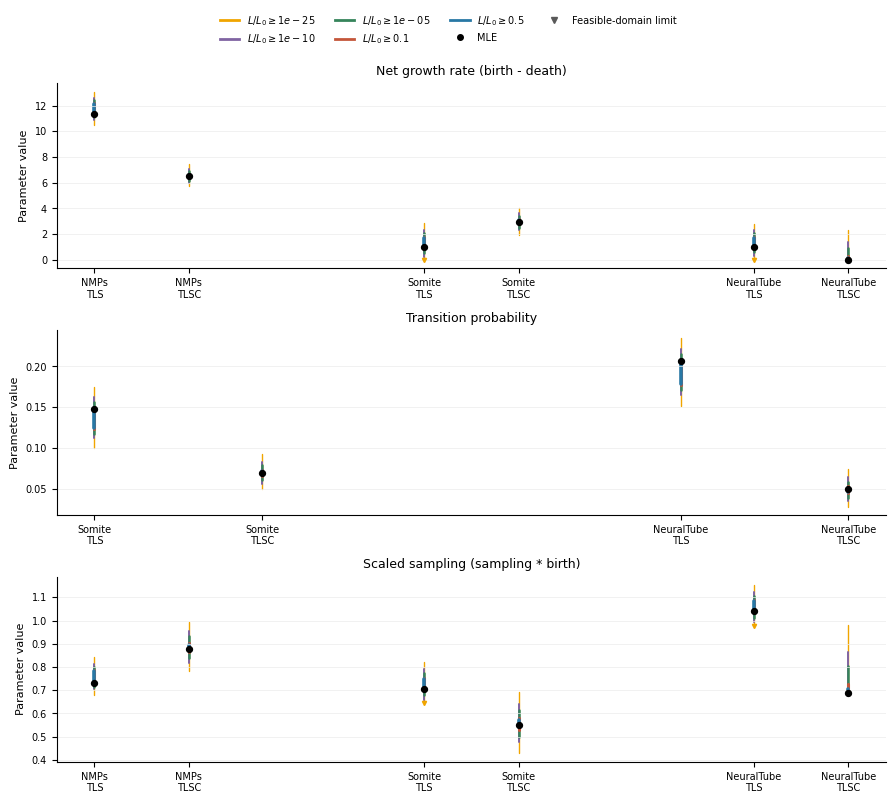

In [42]:
def plot_composite_sensitivity():
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from matplotlib.lines import Line2D

    composite_datasets = ["TLS", "TLSC"]
    composite_alphas = [0.5, 0.1, 1e-5, 1e-10, 1e-25]
    composite_fraction_order = sorted(composite_alphas)
    composite_fraction_colors = {
        composite_alphas[0]: "#2878a5",
        composite_alphas[1]: "#c4563a",
        composite_alphas[2]: "#36845b",
        composite_alphas[3]: "#8064a2",
        composite_alphas[4]: "#f0a500",
    }
    composite_panels = [
        ("Net growth rate (birth - death)", "growth"),
        ("Transition probability", "transition"),
        ("Scaled sampling (sampling * birth)", "scaled_sampling"),
    ]

    composite_ranges = {}
    composite_metadata = {}
    for dataset in composite_datasets:
        output_dir = Path(f"../data/troupe/figures/{dataset}")
        composite_ranges[dataset] = pd.read_csv(
            output_dir / "composite_parameter_value_ranges.csv"
        )
        required_range_columns = {
            "lower_bound_is_domain_limit",
            "higher_bound_is_domain_limit",
        }
        missing_range_columns = required_range_columns.difference(
            composite_ranges[dataset].columns
        )
        if missing_range_columns:
            raise ValueError(
                f"{dataset} composite range CSV is missing columns "
                f"{sorted(missing_range_columns)}; rerun the composite preprocessing cell."
            )
        composite_metadata[dataset] = pd.read_csv(
            output_dir / "composite_parameter_metadata.csv"
        )

    expected_parameters = set(composite_metadata["TLS"]["parameter"])
    for dataset in composite_datasets:
        if set(composite_metadata[dataset]["parameter"]) != expected_parameters:
            raise ValueError(f"Composite parameter sets differ for dataset {dataset}")

    fig, axes = plt.subplots(3, 1, figsize=(9.0, 8.0), constrained_layout=False)
    for ax, (panel_title, parameter_type) in zip(axes, composite_panels):
        parameters = (
            composite_metadata["TLS"]
            .query("parameter_type == @parameter_type")
            .sort_values("parameter_index")
            .reset_index(drop=True)
        )
        xticks = []
        xticklabels = []
        group_spacing = 2.8
        dataset_offset = 0.8

        for parameter_position, (_, parameter_row) in enumerate(parameters.iterrows()):
            parameter = parameter_row["parameter"]
            state_index = int(parameter_row["parameter_index"])
            if parameter_type == "transition":
                category_label = ["NMPs", "Somite", "NeuralTube"][state_index]
            else:
                category_label = ["NMPs", "Somite", "NeuralTube"][state_index]
            x_tls = parameter_position * group_spacing
            for x, dataset in ((x_tls, "TLS"), (x_tls + dataset_offset, "TLSC")):
                ranges = composite_ranges[dataset]
                metadata = composite_metadata[dataset]
                parameter_ranges = ranges[ranges["parameter"] == parameter]
                fraction_index = parameter_ranges["likelihood_fraction"].to_numpy(dtype=float)
                mle_rows = metadata[metadata["parameter"] == parameter]
                if len(mle_rows) != 1:
                    raise ValueError(
                        f"Expected one metadata row for {parameter} in {dataset}; "
                        f"found {len(mle_rows)}"
                    )
                mle = float(mle_rows["original_value"].iloc[0])

                for linewidth, alpha in zip(
                    [1.0, 1.4, 1.8, 2.2, 2.6],
                    composite_fraction_order,
                ):
                    matches = np.flatnonzero(
                        np.isclose(fraction_index, alpha, rtol=1e-12, atol=0.0)
                    )
                    if matches.size != 1:
                        raise KeyError(
                            f"Expected one row for {parameter}, fraction {alpha}, {dataset}; "
                            f"found {matches.size}"
                        )
                    row = parameter_ranges.iloc[matches[0]]
                    low = float(row["lower_parameter_value"])
                    high = float(row["higher_parameter_value"])
                    if np.isfinite(low) and np.isfinite(high):
                        ax.plot(
                            [x, x],
                            [low, high],
                            color=composite_fraction_colors[alpha],
                            linewidth=linewidth,
                            solid_capstyle="round",
                            zorder=1,
                        )
                        if bool(row["lower_bound_is_domain_limit"]):
                            ax.plot(
                                x, low, marker="v", color=composite_fraction_colors[alpha],
                                markersize=3, linestyle="", zorder=2,
                            )
                        if bool(row["higher_bound_is_domain_limit"]):
                            ax.plot(
                                x, high, marker="^", color=composite_fraction_colors[alpha],
                                markersize=3, linestyle="", zorder=2,
                            )

                ax.scatter(x, mle, s=18, color="black", zorder=3)
                xticks.append(x)
                xticklabels.append(f"{category_label}\n{dataset}")

        ax.set_title(panel_title)
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels)
        ax.set_ylabel("Parameter value")
        ax.grid(axis="y", color="0.92", linewidth=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    legend_elements = [
        Line2D(
            [0], [0], color=composite_fraction_colors[alpha], lw=2,
            label=rf"$L/L_0 \geq {alpha:g}$",
        )
        for alpha in composite_fraction_order
    ]
    legend_elements.append(
        Line2D([0], [0], marker="o", color="black", linestyle="", markersize=4, label="MLE")
    )
    legend_elements.append(
        Line2D(
            [0], [0], marker="v", color="0.35", linestyle="", markersize=4,
            label="Feasible-domain limit",
        )
    )
    fig.legend(
        handles=legend_elements,
        loc="upper center",
        ncol=4,
        frameon=False,
        fontsize=7,
        bbox_to_anchor=(0.5, 1.0),
    )
    fig.tight_layout(rect=[0, 0, 1, 0.94])

    figure_dir = Path("../data/troupe/figures")
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / "TLS_vs_TLSC_composite_sensitivity.pdf", bbox_inches="tight")
    fig.savefig(figure_dir / "TLS_vs_TLSC_composite_sensitivity.svg", bbox_inches="tight")
    plt.show()
plot_composite_sensitivity()
